# De la série temporelle aux indicateurs thermiques d'un bâtiment

**Assessment de stage coEnergy — Jihane**

Rapport exécutable : compréhension du problème, analyse exploratoire, protocole, modèles, résultats et limites. Le code réutilisable (chargement, canaux d'entrée, codage des cibles, modèles PyTorch, entraînement, métriques, figures) est dans le package `coenergy_assessment` (`src/`) ; le notebook orchestre et commente.

**Plan**

1. Compréhension du problème
2. Configuration et chargement des données
3. Analyse exploratoire
4. Protocole d'évaluation
5. Modèles
6. Entraînement : une cellule par modèle
7. Comparaison sur la validation
8. Modèle retenu : test et analyse des erreurs
9. Limites et perspectives

## 1. Compréhension du problème

### 1.1 Évaluer un bâtiment par ses indicateurs thermiques

La performance thermique d'un bâtiment se résume par quelques indicateurs, qui décrivent ses déperditions et son inertie. Pour les déterminer, on soumet le bâtiment à une **excitation thermique** (une puissance de chauffage connue) et l'on suit l'évolution de sa température intérieure. Dans un cas théorique idéal, chaque indicateur se lit directement sur cette réponse :

| Famille | Indicateur | Unité | Signification | Détermination dans le cas théorique |
|---|---|---|---|---|
| HLC | `HLC` | W/K | Déperditions totales par transmission | Puissance constante jusqu'à l'équilibre : $\text{HLC} = P / (T_{int} - T_{ext})$ |
| Hb | `HLC_ext` | W/K | Part des déperditions vers l'extérieur et le sol | Même essai, en mesurant le flux à travers les parois extérieures |
| Hb | `HLC_mit` | W/K | Part des déperditions vers les espaces mitoyens non chauffés | Même essai, en mesurant le flux vers les espaces mitoyens |
| CDT | `tau_b` | h | Inertie structurelle globale | Saturer toute la masse du bâti, couper le chauffage, mesurer la décharge |
| CDT | `tau_n` | h | Persistance de la fraîcheur nocturne (confort d'été) | Refroidir l'air pendant 8 h, mesurer combien de temps la fraîcheur persiste |
| CDT | `tau_inf` | h | Temps de séjour moyen de la chaleur | Refroidir l'air indéfiniment, puis mesurer le retour à l'équilibre |

Deux contraintes physiques relient ces indicateurs : $\text{HLC} = \text{HLC}_{ext} + \text{HLC}_{mit}$ et $\tau_n < \tau_\infty < \tau_b$ (plus la sollicitation pénètre profondément dans les parois, plus la décharge est lente). Ces essais idéaux supposent un régime permanent, des conditions extérieures constantes et une durée de plusieurs fois la plus grande constante de temps, soit des jours à des semaines.

### 1.2 En réalité : un modèle soumis à plusieurs incertitudes

$$P_{chauffage} + P_{solaire} + P_{internes} = (\text{HLC} + H_{air})\,(T_{int} - T_{ext}) + C\,\frac{dT_{int}}{dt}$$

- **Inertie** : avant l'équilibre, une partie de la chaleur est stockée dans les parois ; l'élévation de température mélange déperditions et stockage.
- **État initial** : la température dans l'épaisseur des parois est inconnue et fait dériver $T_{int}$ même sans chauffage.
- **Conditions extérieures** : température extérieure, ensoleillement et espaces mitoyens varient pendant la mesure.
- **Apports parasites et mesure** : soleil, occupants, infiltrations ; précision et résolution des capteurs.
- **Durée** : une mesure courte n'observe qu'une partie de la dynamique des constantes de temps longues.

### 1.3 Formulation

Le bâtiment est décrit par une représentation d'état linéaire, $C\,\dot T = A\,T + E\,U$. La **formule de Duhamel** (superposition) donne exactement :

$$T_{int}(t) = T_{libre}(t) + (h * U)(t), \qquad (h * U)(t) = \int_0^t h(t-s)\,U(s)\,ds$$

- $T_{libre}$ : évolution sans chauffage, due à l'état initial et à la météo.
- $h * U$ : réponse au chauffage, une **convolution** : chaque apport passé $U(s)$ est pondéré par $h(t-s)$ selon son ancienneté. La réponse impulsionnelle $h(t) \propto e^{C^{-1}A\,t}\,C^{-1}E$ est une somme d'exponentielles décroissantes, une par mode thermique.

Les indicateurs sont des propriétés de $h$ : $\text{HLC} = 1 / \int_0^\infty h(s)\,ds$ (inverse du gain statique) et les constantes de temps sont ses rythmes de décroissance. C'est aussi le principe des méthodes de facteurs de réponse en thermique du bâtiment, et ce qui motive des réseaux **convolutifs** : le modèle apprend la relation inverse $(T_{int}, U) \rightarrow$ indicateurs.

### 1.4 Les données de ce problème

Les données suivent la démarche de l'article de coEnergy (Nassif *et al.*) : une **population de variantes** du bâtiment `quentin_house`, de même géométrie mais aux propriétés thermophysiques tirées par Monte-Carlo, chacune simulée avec une excitation de chauffage aléatoire, sous la même météo. Les indicateurs sont calculés exactement à partir des matrices du modèle.

- **Durée.** 480 mesures de $T_{int}$ et de $U$ par simulation. Avec un pas d'une minute, comme dans l'article, la séquence couvre **8 h** (30 s donneraient 4 h, 3 min 24 h) : c'est une hypothèse.
- **Excitation.** L'article utilise des sinusoïdes et des PRBS ; ici, toutes les excitations sont des **PRBS** tout-ou-rien (0 ou 7 kW).
- **Simulations sans excitation.** Environ 8,5 % ne reçoivent aucun chauffage. Elles sont **conservées**, avec un découpage stratifié, pour que le modèle apprenne à ne pas inventer une valeur précise quand la courbe est peu informative ; les performances sont données par régime.
- **Objectif.** L'article ne prédit que le HLC ; ici, les six indicateurs sont prédits par un seul modèle, contraintes physiques imposées par construction.

### 1.5 Observabilité attendue en 8 heures

| Indicateur | Ordre de grandeur | Observabilité |
|---|---|---|
| HLC | ≈ 230 W/K | Révélé par la réponse au chauffage, mais confondu avec l'inertie loin de l'équilibre |
| HLC_mit, HLC_ext | ≈ 120 et 110 W/K | Difficiles à séparer : les températures mitoyennes ne sont pas mesurées |
| `tau_n` | ≈ 11 h | Le plus observable : même ordre que la durée de mesure |
| `tau_inf`, `tau_b` | ≈ 31 et 50 h | Quasi invisibles : après 8 h, $e^{-8/40} \approx 0{,}82$ contre $e^{-8/60} \approx 0{,}87$ |

## 2. Configuration et chargement des données

- `QUICK = True` : essai de quelques minutes sur un sous-ensemble.
- `RETRAIN = False` : recharge les modèles déjà sauvegardés dans `outputs/checkpoints/` au lieu de les réentraîner.

In [3]:
import json
import shutil
import sys
import time
from dataclasses import asdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

# ----------------------------------------------------------------------------- réglages
QUICK = False        # True : essai rapide (sous-ensemble, 1 époque)
RETRAIN = False      # True : réentraîner même si un modèle sauvegardé existe
EPOCHS = 20          # époques par modèle
SEED = 42
NOISE_C = 0.25       # bruit de capteur testé (°C) : précision typique des sondes de l'article

# ----------------------------------------------------------------------------- chemins
ON_KAGGLE = Path("/kaggle/input").exists()
ROOT = Path("/kaggle/working") if ON_KAGGLE else Path(".").resolve()
SEARCH = Path("/kaggle/input") if ON_KAGGLE else ROOT


def find_parent(pattern: str) -> Path:
    # Dossier contenant le premier fichier correspondant au motif (recherche récursive)
    hits = sorted(SEARCH.rglob(pattern))
    if not hits:
        raise FileNotFoundError(f"{pattern} introuvable sous {SEARCH}")
    return hits[0].parent


DATA = find_parent("T.npy")                                  # T.npy, U.npy, Y.npy, target_names.npy
try:
    import coenergy_assessment as ca
except ModuleNotFoundError:                                  # package non installé (Kaggle)
    src = find_parent("targets.py")
    if src.name != "coenergy_assessment":                    # fichiers déposés à plat : on recrée le dossier
        pkg = ROOT / "_pkg" / "coenergy_assessment"
        pkg.mkdir(parents=True, exist_ok=True)
        for f in src.glob("*.py"):
            shutil.copy(f, pkg / f.name)
        src = pkg
    sys.path.insert(0, str(src.parent))
    import coenergy_assessment as ca
from coenergy_assessment import plots

OUT = ROOT / ("outputs_quick" if QUICK else "outputs")      # l'essai rapide ne touche pas aux vrais résultats
CKPT, RES = OUT / "checkpoints", OUT / "results"
CKPT.mkdir(parents=True, exist_ok=True)
RES.mkdir(parents=True, exist_ok=True)
if ON_KAGGLE:                                                # reprise : modèles d'une exécution précédente
    for f in SEARCH.rglob("checkpoints/*.pt"):
        if not (CKPT / f.name).exists():
            shutil.copy(f, CKPT / f.name)
    print("Modèles déjà disponibles :", sorted(f.stem for f in CKPT.glob("*.pt")))

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(SEED)
plots.set_style()
pd.options.display.float_format = "{:.3f}".format

print("Appareil :", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")
print("Données  :", DATA)
print("Sorties  :", OUT)

Modèles déjà disponibles : []
Appareil : cuda Tesla T4
Données  : /kaggle/input/datasets/jiihan/coenergy
Sorties  : /kaggle/working/outputs


Les batchs bruts ont été convertis une seule fois avec `ca.prepare_data` : température en centièmes de degré et puissance en watts, en `int16`, soit 1,9 Go au lieu de 3,8 Go, sans perte.

In [4]:
data = ca.load_data(DATA, n=20_000 if QUICK else None)
N, L = len(data), data.seq_len
targets, hours = data.targets, data.hours
Y = data.Y

print(f"{N:,} simulations de {L} pas d'une minute ({L / 60:.0f} h)".replace(",", " "))
print("Indicateurs :", targets)

1 000 000 simulations de 480 pas d'une minute (8 h)
Indicateurs : ['HLC', 'HLC_mit', 'HLC_ext', 'tau_b', 'tau_n', 'tau_inf']


## 3. Analyse exploratoire

### 3.1 Statistiques des indicateurs

In [5]:
stats = pd.DataFrame({
    "unité": [ca.UNITS[t] for t in targets],
    "moyenne": Y.mean(0).numpy(), "écart-type": Y.std(0).numpy(),
    "min": Y.amin(0).numpy(), "médiane": Y.median(0).values.numpy(), "max": Y.amax(0).numpy(),
    "asymétrie": (((Y - Y.mean(0)) / Y.std(0)) ** 3).mean(0).numpy(),
}, index=targets)
stats["CV (%)"] = 100 * stats["écart-type"] / stats["moyenne"]
display(stats.round(2))

,unité,moyenne,écart-type,min,médiane,max,asymétrie,CV (%)
HLC,W/K,232.930,31.330,111.400,231.800,368.000,0.180,13.450
HLC_mit,W/K,120.490,26.260,42.840,118.900,231.530,0.280,21.790
HLC_ext,W/K,112.440,17.110,52.650,112.190,185.890,0.100,15.220
tau_b,h,50.000,10.100,20.200,48.820,122.880,0.710,20.190
tau_n,h,11.040,2.010,5.170,10.790,25.840,0.750,18.200
tau_inf,h,31.230,7.530,10.480,30.200,93.120,0.850,24.110


### 3.2 Distributions des indicateurs

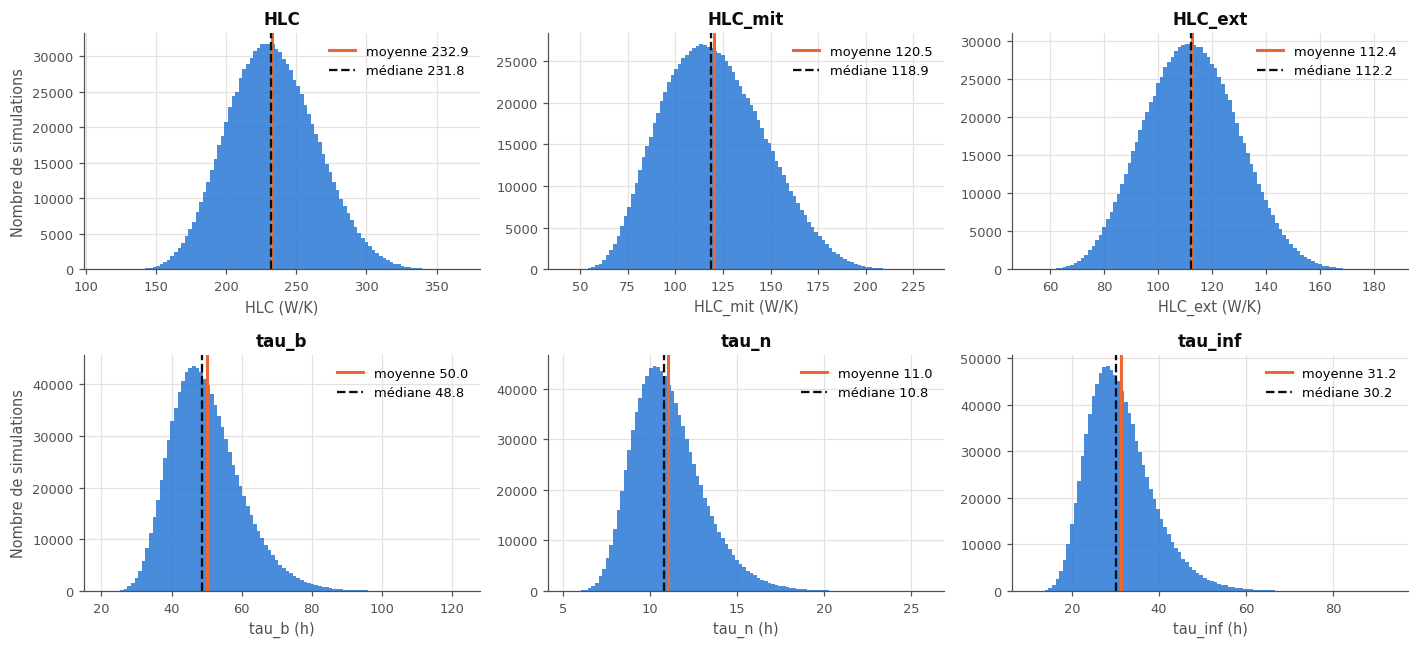

In [6]:
fig = plots.plot_target_distributions(Y, targets)
plt.show()

Les HLC sont presque symétriques ; les constantes de temps sont étalées vers les grandes valeurs (rapport $C/H$), d'où le passage au logarithme dans le codage des cibles. Le coefficient de variation (13 à 25 %) fixe l'échelle : la moyenne sert de plancher.

### 3.3 Contraintes physiques et unicité des simulations

In [7]:
c = data.col
somme = (Y[:, c("HLC")] - Y[:, c("HLC_mit")] - Y[:, c("HLC_ext")]).abs().max().item()
ordre = ((Y[:, c("tau_n")] < Y[:, c("tau_inf")]) & (Y[:, c("tau_inf")] < Y[:, c("tau_b")])).float().mean().item()
n_unique = torch.unique(Y, dim=0).shape[0]

print(f"Écart maximal |HLC - HLC_mit - HLC_ext| : {somme:.1e} W/K (précision float32)")
print(f"Simulations vérifiant tau_n < tau_inf < tau_b : {ordre:.2%}")
print(f"Vecteurs d'indicateurs distincts : {n_unique:,} sur {N:,}".replace(",", " "))

Écart maximal |HLC - HLC_mit - HLC_ext| : 3.1e-05 W/K (précision float32)
Simulations vérifiant tau_n < tau_inf < tau_b : 100.00%
Vecteurs d'indicateurs distincts : 1 000 000 sur 1 000 000


Les deux contraintes sont vérifiées sur toutes les simulations : elles peuvent être imposées au modèle. Chaque simulation est une variante distincte du bâtiment : pas de fuite entre ensembles.

### 3.4 Corrélations entre indicateurs

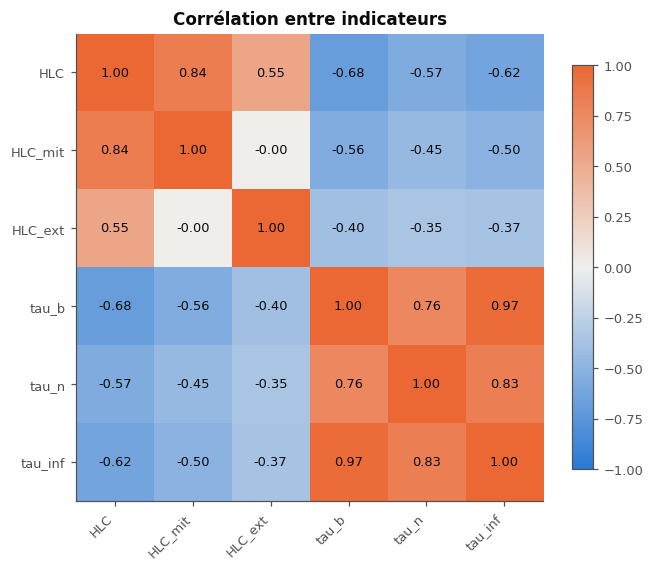

In [8]:
fig = plots.plot_correlation(Y, targets)
plt.show()

`HLC_mit` et `HLC_ext` sont indépendants ; `tau_b` et `tau_inf` sont presque redondants, ce qui justifie un modèle multi-sorties. HLC et constantes de temps sont anticorrélés ($\tau \sim C/H$).

### 3.5 Les signaux d'entrée et les régimes d'excitation

In [9]:
P_MAX = float(data.U.max())
u_values = torch.unique(data.U[:20_000])
t0 = data.T[:, 0].float() / 100
t_min, t_max = data.T.amin().item() / 100, data.T.amax().item() / 100

print(f"Valeurs prises par U : {u_values.tolist()} W  ->  signal tout-ou-rien, P_max = {P_MAX:.0f} W")
print(f"Température initiale T(0) : de {t0.min().item():.2f} à {t0.max().item():.2f} °C")
print(f"Température sur l'ensemble des simulations : de {t_min:.2f} à {t_max:.2f} °C")

GROUPS = ca.excitation_groups(data.U, P_MAX)
display(pd.DataFrame({"simulations": {k: int(v.sum()) for k, v in GROUPS.items()},
                      "part (%)": {k: 100 * v.float().mean().item() for k, v in GROUPS.items()}}).round(2))

Valeurs prises par U : [0, 7000] W  ->  signal tout-ou-rien, P_max = 7000 W
Température initiale T(0) : de 24.62 à 24.62 °C
Température sur l'ensemble des simulations : de 24.22 à 51.55 °C


,simulations,part (%)
avec créneaux,907125,90.710
sans excitation,84164,8.420
toujours allumé,8711,0.870


La puissance ne prend que deux valeurs (PRBS). Trois régimes : **sans excitation**, **toujours allumé**, **avec créneaux**. Toutes les simulations partent de la même température d'air : seule la dynamique distingue les bâtiments.

### 3.6 Exemples de simulations

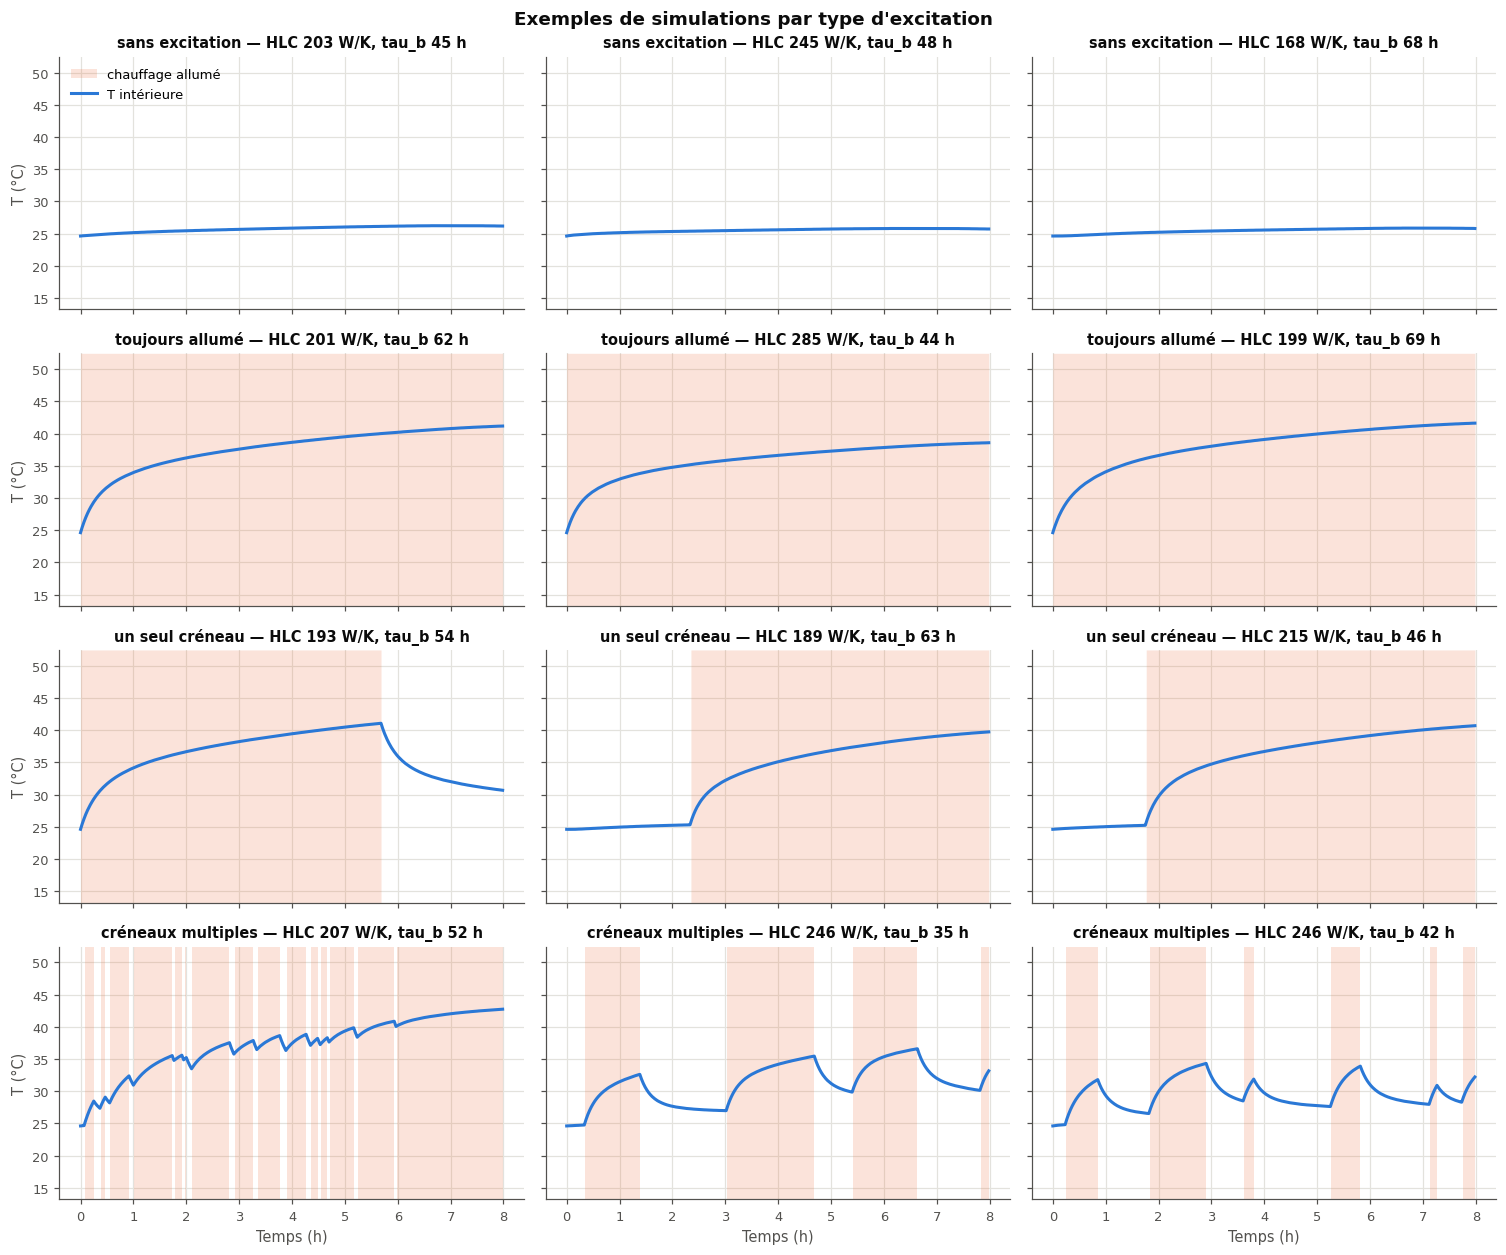

In [10]:
g = torch.Generator().manual_seed(SEED)
desc = ca.describe_excitations(data.U)

# Deux exemples par type de signal : sans chauffe, toujours allumé, un créneau, créneaux multiples
kinds = {
    "sans excitation": GROUPS["sans excitation"],
    "toujours allumé": GROUPS["toujours allumé"],
    "un seul créneau": GROUPS["avec créneaux"] & (desc["n_creneaux"] == 1),
    "créneaux multiples": GROUPS["avec créneaux"] & (desc["n_creneaux"] >= 4),
}
ex_idx, ex_titles = [], []
for name, mask in kinds.items():
    idx = mask.nonzero().squeeze(1)
    if len(idx) == 0:
        continue
    for i in idx[torch.randperm(len(idx), generator=g)[:3]]:
        ex_idx.append(int(i))
        ex_titles.append(f"{name} — HLC {Y[i, c('HLC')]:.0f} W/K, tau_b {Y[i, c('tau_b')]:.0f} h")
ex_idx = torch.tensor(ex_idx)
fig = plots.plot_trajectories(hours, data.temperature(ex_idx), data.power(ex_idx), ex_titles,
                              "Exemples de simulations par type d'excitation")
plt.show()

Chaque allumage produit une montée rapide (l'air) puis lente (les parois) : un système à plusieurs constantes de temps. L'amplitude renseigne sur les déperditions, la courbure sur l'inertie.

### 3.7 Descripteurs des excitations

In [11]:
desc_table = pd.DataFrame({
    name: {"définies": int((~v.isnan()).sum()), "moyenne": v.nanmean().item(),
           "min": v[~v.isnan()].min().item(), "médiane": v.nanmedian().item(),
           "max": v[~v.isnan()].max().item()}
    for name, v in desc.items()}).T
display(desc_table.round(2))

special = {
    "un seul créneau de chauffe": kinds["un seul créneau"],
    "au moins 4 créneaux": kinds["créneaux multiples"],
    "chauffe seulement dans la dernière heure": desc["premier_allumage_h"] >= L / 60 - 1,
    "plus de 100 commutations": desc["n_commutations"] > 100,
}
display(pd.DataFrame({"part (%)": {k: 100 * m.float().mean().item() for k, m in special.items()}}).round(2))

,définies,moyenne,min,médiane,max
energie_kWh,1000000.000,26.250,0.000,29.980,56.000
taux_allumage,1000000.000,0.470,0.000,0.540,1.000
n_commutations,1000000.000,6.180,0.000,2.000,240.000
n_creneaux,1000000.000,3.340,0.000,1.000,120.000
duree_creneau_h,915836.000,3.220,0.020,3.110,8.000
premier_allumage_h,915836.000,1.980,0.000,1.630,7.980
instant_moyen_h,915836.000,4.510,2.000,4.430,7.980


,part (%)
un seul créneau de chauffe,60.290
au moins 4 créneaux,11.510
chauffe seulement dans la dernière heure,2.050
plus de 100 commutations,1.440


### 3.8 Distributions des descripteurs

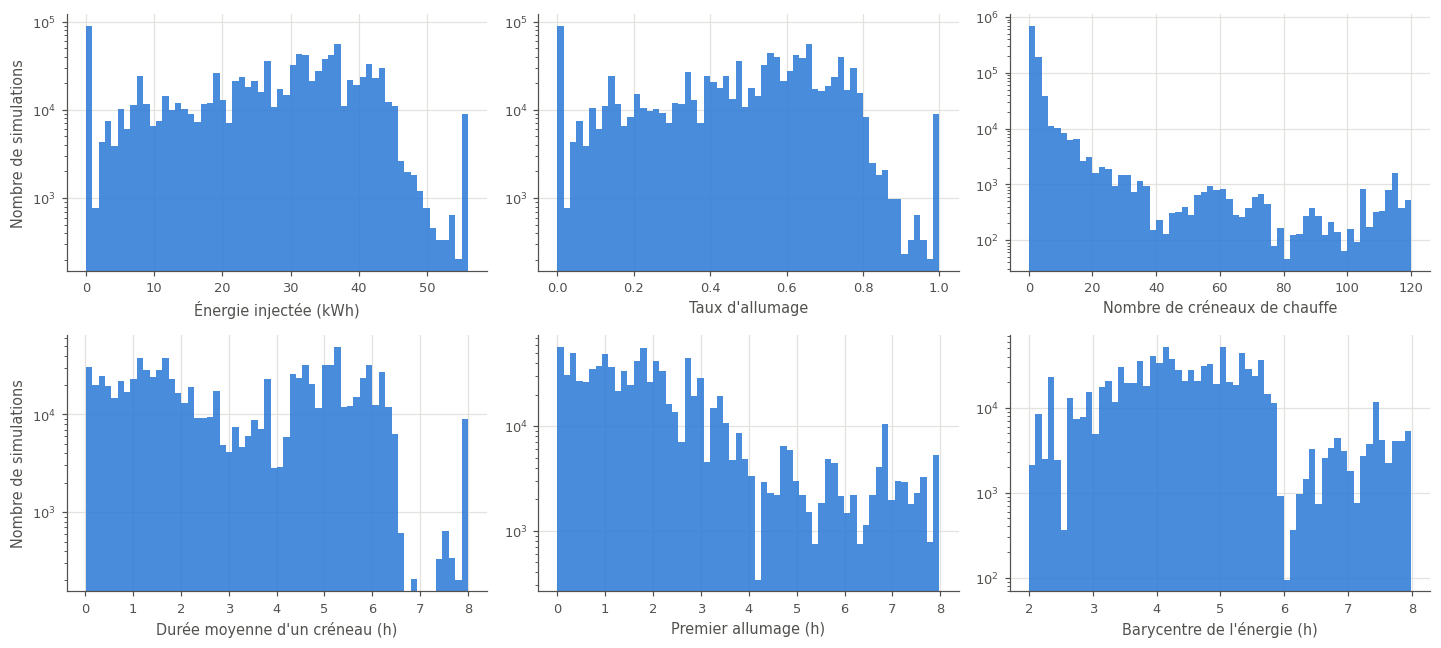

In [12]:
fig = plots.plot_histograms(
    {k: desc[k] for k in ["energie_kWh", "taux_allumage", "n_creneaux", "duree_creneau_h",
                          "premier_allumage_h", "instant_moyen_h"]},
    {"energie_kWh": "Énergie injectée (kWh)", "taux_allumage": "Taux d'allumage",
     "n_creneaux": "Nombre de créneaux de chauffe", "duree_creneau_h": "Durée moyenne d'un créneau (h)",
     "premier_allumage_h": "Premier allumage (h)", "instant_moyen_h": "Barycentre de l'énergie (h)"},
    log=True)
plt.show()

L'énergie injectée couvre toute la plage (0 à 56 kWh). La plupart des signaux sont des PRBS à blocs longs, peu riches en fréquences ; quelques-uns ne chauffent qu'en fin de séquence, ce qui laisse une réponse très courte.

### 3.9 La réponse libre

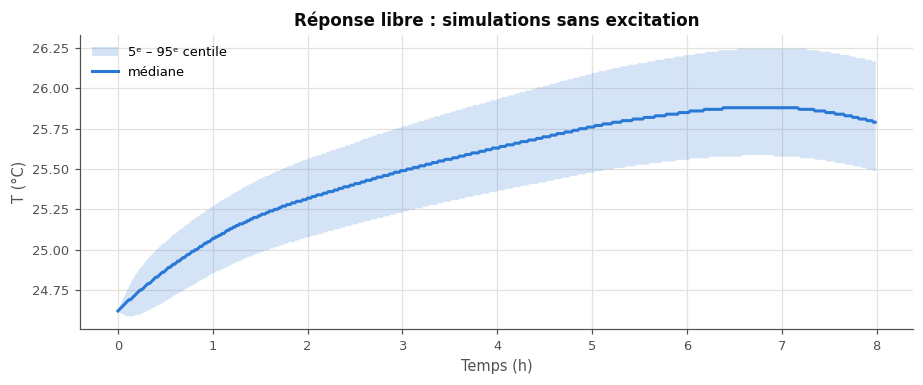

Dérive sur 8 h sans chauffage : médiane +1.17 °C, de +0.45 à +2.35 °C


In [13]:
free_idx = GROUPS["sans excitation"].nonzero().squeeze(1)[:20_000]
t_free_all = data.temperature(free_idx)
fig = plots.plot_free_response(hours, t_free_all)
plt.show()

drift = t_free_all[:, -1] - t_free_all[:, 0]
print(f"Dérive sur 8 h sans chauffage : médiane {drift.median().item():+.2f} °C, "
      f"de {drift.min().item():+.2f} à {drift.max().item():+.2f} °C")

Sans chauffage, toutes les simulations suivent la même tendance, imposée par la météo commune : c'est $T_{libre}$. La retrancher isole approximativement la réponse au chauffage (canal `T − T_libre`).

### 3.10 Ce que les entrées disent des cibles : chauffage permanent

Toutes ces simulations reçoivent la même excitation : seul le bâtiment change.

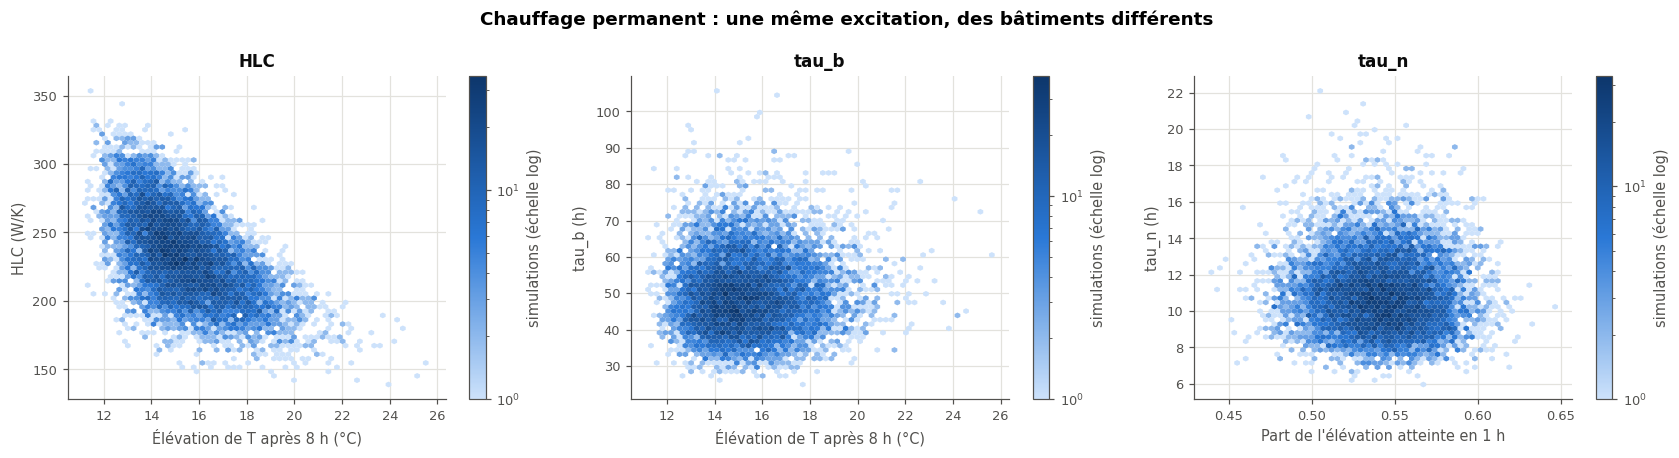

In [14]:
on_idx = GROUPS["toujours allumé"].nonzero().squeeze(1)
t_on = data.temperature(on_idx)
rise_1h, rise_8h = t_on[:, 59] - t_on[:, 0], t_on[:, -1] - t_on[:, 0]

fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.2))
plots.plot_density(rise_8h, Y[on_idx, c("HLC")], "Élévation de T après 8 h (°C)", "HLC (W/K)",
                   "HLC", ax=axes[0])
plots.plot_density(rise_8h, Y[on_idx, c("tau_b")], "Élévation de T après 8 h (°C)", "tau_b (h)",
                   "tau_b", ax=axes[1])
plots.plot_density(rise_1h / rise_8h, Y[on_idx, c("tau_n")], "Part de l'élévation atteinte en 1 h",
                   "tau_n (h)", "tau_n", ax=axes[2])
fig.suptitle("Chauffage permanent : une même excitation, des bâtiments différents", fontweight="bold")
fig.tight_layout()
plt.show()

In [15]:
feats = {"élévation à 1 h": rise_1h, "élévation à 8 h": rise_8h, "rapport 1 h / 8 h": rise_1h / rise_8h}
corr_on = pd.DataFrame({name: [torch.corrcoef(torch.stack([f, Y[on_idx, j]]))[0, 1].item()
                               for j in range(6)] for name, f in feats.items()}, index=targets)
print("Chauffage permanent — corrélation entre un résumé de T(t) et chaque indicateur :")
display(corr_on.round(2))

Chauffage permanent — corrélation entre un résumé de T(t) et chaque indicateur :


,élévation à 1 h,élévation à 8 h,rapport 1 h / 8 h
HLC,-0.510,-0.590,0.240
HLC_mit,-0.470,-0.520,0.180
HLC_ext,-0.230,-0.290,0.180
tau_b,0.070,0.030,0.090
tau_n,-0.350,-0.310,-0.040
tau_inf,-0.070,-0.100,0.100


À puissance égale, le HLC est le plus lié à l'élévation finale (−0,59) et `tau_n` à celle de la première heure (−0,35) ; `tau_b` et `tau_inf` n'y sont presque pas liés ($|r| \le 0{,}10$), comme prévu en 1.5.

### 3.11 Ce que les entrées disent des cibles : sans excitation

In [16]:
drift_all = data.temperature(GROUPS["sans excitation"].nonzero().squeeze(1))
drift_all = drift_all[:, -1] - drift_all[:, 0]
y_free = Y[GROUPS["sans excitation"]]
print("Sans excitation — corrélation entre la dérive de T sur 8 h et chaque indicateur :")
display(pd.DataFrame({"dérive sur 8 h": [torch.corrcoef(torch.stack([drift_all, y_free[:, j]]))[0, 1].item()
                                          for j in range(6)]}, index=targets).round(2))

Sans excitation — corrélation entre la dérive de T sur 8 h et chaque indicateur :


,dérive sur 8 h
HLC,-0.180
HLC_mit,-0.190
HLC_ext,-0.040
tau_b,-0.190
tau_n,-0.230
tau_inf,-0.200


Sans excitation, la dérive sur 8 h est faiblement liée au HLC et aux constantes de temps ($|r| \approx 0{,}2$) et pas du tout à `HLC_ext` (−0,04) : si `HLC_ext` reste estimable sans chauffage (7.5), c'est par la forme de la courbe, pas par la dérive totale.

À excitation identique, l'élévation de température est liée au HLC, mais sous forme d'un nuage épais : un résumé de la série ne suffit pas, d'où un modèle séquentiel. Sans excitation, le lien est plus faible.

### 3.12 Synthèse

| Constat | Conséquence |
|---|---|
| Deux contraintes physiques exactes | Codage des cibles qui les respecte par construction |
| Constantes de temps asymétriques et corrélées | Logarithme ; un seul modèle multi-sorties |
| Trois régimes d'excitation inégalement informatifs | Découpage stratifié ; métriques par régime |
| Même météo et même T(0) | Normalisation globale de T ; canal `T − T_libre` |
| L'amplitude de la réponse porte le HLC | Pas de normalisation par simulation |
| `tau_b`, `tau_inf` presque indépendants des résumés de $T$ | S'attendre à des prédictions proches de la moyenne |

## 4. Protocole d'évaluation

### 4.1 Découpage

Entraînement 80 %, validation 10 %, test 10 %, **stratifiés par régime d'excitation**. Les statistiques de normalisation viennent de l'entraînement ; la validation choisit les modèles ; le test n'est utilisé qu'une fois.

In [17]:
SPLITS = ca.make_splits(GROUPS, None if QUICK else DATA / "splits.pt" if (DATA / "splits.pt").exists()
                        else OUT / "splits.pt", seed=SEED)
display(pd.DataFrame({split: {"simulations": len(idx),
                              **{f"{k} (%)": 100 * m[idx].float().mean().item() for k, m in GROUPS.items()}}
                      for split, idx in SPLITS.items()}).T.round(2))

assert len(set(SPLITS["train"].tolist()) & set(SPLITS["test"].tolist())) == 0
assert len(set(SPLITS["val"].tolist()) & set(SPLITS["test"].tolist())) == 0
print("Aucune simulation commune entre les ensembles.")

,simulations,avec créneaux (%),sans excitation (%),toujours allumé (%)
train,800002.000,90.710,8.420,0.870
val,99999.000,90.710,8.420,0.870
test,99999.000,90.710,8.420,0.870


Aucune simulation commune entre les ensembles.


### 4.2 Entrées du réseau

| Jeu | Canaux |
|---|---|
| `base` (2) | température normalisée (moyenne et écart-type globaux), $U / P_{max}$ |
| `physique` (5) | les deux précédents, `T − T_libre`, `T − T(0)`, temps normalisé |

T : moyenne 30.56 °C, écart-type 4.79 °C
Écart-type de T - T_libre : 4.61 °C | de T - T(0) : 4.79 °C


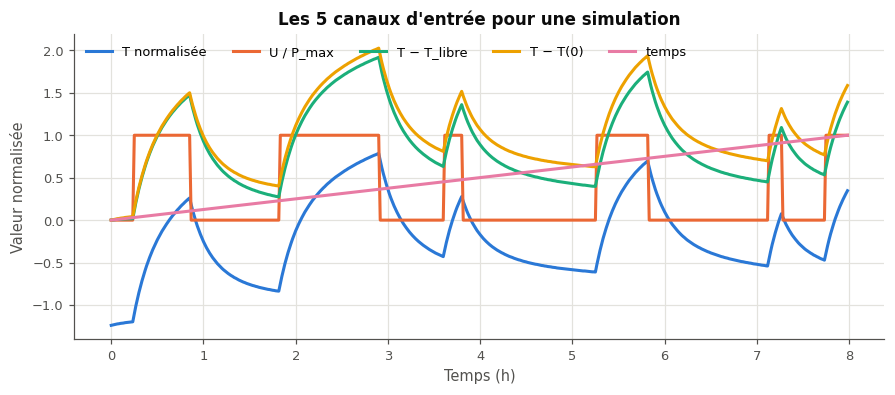

In [18]:
scaler = ca.InputScaler.fit(data, SPLITS["train"], GROUPS["sans excitation"], P_MAX)
print(f"T : moyenne {scaler.t_mu:.2f} °C, écart-type {scaler.t_sd:.2f} °C")
print(f"Écart-type de T - T_libre : {scaler.d_free_sd:.2f} °C | de T - T(0) : {scaler.d_t0_sd:.2f} °C")

x = scaler.build(data.temperature(ex_idx[-1:]), data.power(ex_idx[-1:]), "physique")[0]
fig, ax = plt.subplots(figsize=(9.5, 3.6))
for k, name in enumerate(["T normalisée", "U / P_max", "T − T_libre", "T − T(0)", "temps"]):
    ax.plot(hours, x[k].numpy(), label=name)
ax.set(xlabel="Temps (h)", ylabel="Valeur normalisée", title="Les 5 canaux d'entrée pour une simulation")
ax.legend(ncols=5, loc="upper left")
plt.show()

Toutes les simulations partant de la même température (3.5), $T - T(0)$ n'est qu'une translation de $T$ : même écart-type (4,79 °C), donc aucune information nouvelle. Les canaux physiques restent des fonctions de $T$ et du temps.

### 4.3 Codage des cibles

Le réseau produit 5 sorties : le HLC est **reconstruit** comme $\text{HLC}_{ext} + \text{HLC}_{mit}$.

| Codage | Sorties | Ordre des constantes de temps |
|---|---|---|
| `contraint` | `HLC_mit`, `HLC_ext`, $\log \tau_n$, $\log(\tau_\infty - \tau_n)$, $\log(\tau_b - \tau_\infty)$ | garanti (écarts positifs par l'exponentielle) |
| `direct` | `HLC_mit`, `HLC_ext`, $\tau_b$, $\tau_n$, $\tau_\infty$ | vérifié après coup |

In [19]:
for encoding in ("contraint", "direct"):
    codec = ca.TargetCodec(encoding, targets).fit(Y[SPLITS["train"]])
    back = codec.inverse(codec.transform(Y[:2000]))
    print(f"Codage {encoding:9s} : erreur maximale d'un aller-retour = {(back - Y[:2000]).abs().max().item():.1e}")

Codage contraint : erreur maximale d'un aller-retour = 3.1e-05
Codage direct    : erreur maximale d'un aller-retour = 3.1e-05


### 4.4 Métriques

Calculées **en unités physiques** sur les indicateurs décodés, par indicateur, par famille et par régime : **RMSE**, **MAE**, **P95** (critère de l'article), **MAPE**, **R²**. Score unique : $\frac{1}{6}\sum \sqrt{1 - R^2}$ (1 = moyenne, 0 = parfait).

## 5. Modèles

### 5.1 Références

- **Moyenne** de l'entraînement : plancher absolu.
- **Régression linéaire régularisée** sur un résumé de la simulation (élévation de température et énergie cumulée toutes les 30 min) : ce qu'un modèle linéaire tire des données.

In [20]:
Y_VAL = Y[SPLITS["val"]]
GROUPS_VAL = {k: m[SPLITS["val"]] for k, m in GROUPS.items()}
VAL_PRED: dict[str, torch.Tensor] = {}       # prédictions de chaque modèle sur la validation

VAL_PRED["Moyenne"] = ca.mean_baseline(Y[SPLITS["train"]], len(Y_VAL))
print("Moyenne (validation)")
display(ca.regression_metrics(Y_VAL, VAL_PRED["Moyenne"], targets).round(3))

Moyenne (validation)


,RMSE,MAE,P95,MAPE,R2
indicateur,,,,,
HLC,31.409,25.353,60.668,11.195,-0.000
HLC_mit,26.256,21.407,49.586,19.012,-0.000
HLC_ext,17.121,13.872,32.902,12.871,-0.000
tau_b,10.163,7.997,19.431,16.484,-0.000
tau_n,2.020,1.584,3.887,14.604,-0.000
tau_inf,7.581,5.928,14.422,19.803,-0.000


In [21]:
ridge_idx = SPLITS["train"][:200_000]
ridge = ca.RidgeBaseline().fit(ca.summary_features(data, ridge_idx), Y[ridge_idx])
VAL_PRED["Régression linéaire"] = ridge.predict(ca.summary_features(data, SPLITS["val"]))
print("Régression linéaire (validation)")
display(ca.regression_metrics(Y_VAL, VAL_PRED["Régression linéaire"], targets).round(3))

Régression linéaire (validation)


,RMSE,MAE,P95,MAPE,R2
indicateur,,,,,
HLC,27.271,21.842,53.202,9.613,0.246
HLC_mit,23.519,18.994,45.435,16.754,0.198
HLC_ext,16.650,13.466,32.143,12.472,0.054
tau_b,10.154,7.988,19.404,16.464,0.002
tau_n,1.916,1.505,3.689,13.824,0.100
tau_inf,7.546,5.904,14.321,19.712,0.009


Un résumé linéaire (élévation de $T$ et énergie cumulée) explique déjà un quart de la variance du HLC (R² 0,25) : c'est le gain statique de $h * U$. Il n'apporte presque rien sur `HLC_ext` (0,05) ni sur `tau_b` et `tau_inf` (≈ 0) : ces indicateurs demandent la forme de la réponse, pas son amplitude.

### 5.2 Réseaux

| Modèle | Architecture | Pourquoi |
|---|---|---|
| **CNN-GRU** | 3 blocs Conv1d (noyau 5) → BatchNorm → GELU → MaxPool ×2 (480 → 60 pas), GRU bidirectionnel 2 couches, états finaux concaténés, tête MLP → 5 | Architecture de l'article : la convolution capte les fronts de montée (structure $h * U$), le GRU la dynamique lente (état thermique) |
| **Transformer à patches** | 30 patches de 16 min → tokens de dimension 64, token `[CLS]`, position apprise, 4 couches d'encodeur (4 têtes), même tête | L'attention relie directement une variation de température au créneau qui l'a causée |

Aucun modèle n'est causal : la séquence entière est observée avant la prédiction.

In [22]:
rows = {}
for name in ("cnn_gru", "transformer"):
    for inputs, n_ch in ca.N_CHANNELS.items():
        model = ca.build_model(name, n_ch, seq_len=L)
        with torch.no_grad():
            out = model(torch.zeros(2, n_ch, L))
        rows[(name, inputs)] = {"canaux": n_ch, "paramètres": ca.count_parameters(model), "sortie": tuple(out.shape)}
display(pd.DataFrame(rows).T)
del model

canaux paramètres  sortie
cnn_gru     base          2     175173  (2, 5)
            physique      5     176133  (2, 5)
transformer base          2     142661  (2, 5)
            physique      5     145733  (2, 5)

Les quatre configurations ont des tailles voisines (143 000 à 176 000 paramètres) : les écarts de performance ne tiennent pas à la capacité.

## 6. Entraînement : une cellule par modèle

Chaque expérience ne change qu'**un seul** élément par rapport au CNN-GRU de référence :

| Question | Expériences comparées |
|---|---|
| Le codage contraint coûte-t-il de la précision ? | CNN-GRU `contraint` / `direct` |
| Les canaux physiques aident-ils ? | chaque architecture avec `base` / `physique` |
| Quelle architecture ? | CNN-GRU / Transformer, entrées et codage identiques |

Réglages communs (`ca.Experiment`) : AdamW, *one-cycle*, lots de 512, écrêtage du gradient, précision mixte sur GPU, même graine ; le modèle conservé est celui de la meilleure époque en validation.

In [23]:
common = dict(epochs=1 if QUICK else EPOCHS, seed=SEED, n_train=1_000 if QUICK else None)

EXPERIMENTS = {
    "CNN-GRU": ca.Experiment("cnn_gru_base_contraint", "cnn_gru", "base", "contraint", **common),
    "CNN-GRU, codage direct": ca.Experiment("cnn_gru_base_direct", "cnn_gru", "base", "direct", **common),
    "CNN-GRU, canaux physiques": ca.Experiment("cnn_gru_physique_contraint", "cnn_gru", "physique", "contraint", **common),
    "Transformer": ca.Experiment("transformer_base_contraint", "transformer", "base", "contraint", **common),
    "Transformer, canaux physiques": ca.Experiment("transformer_physique_contraint", "transformer", "physique", "contraint", **common),
}
display(pd.DataFrame({label: {"modèle": e.model, "entrées": e.inputs, "codage": e.encoding,
                              "époques": e.epochs, "lot": e.batch_size, "lr max": e.lr}
                      for label, e in EXPERIMENTS.items()}).T)

,modèle,entrées,codage,époques,lot,lr max
CNN-GRU,cnn_gru,base,contraint,20,512,0.001
"CNN-GRU, codage direct",cnn_gru,base,direct,20,512,0.001
"CNN-GRU, canaux physiques",cnn_gru,physique,contraint,20,512,0.001
Transformer,transformer,base,contraint,20,512,0.001
"Transformer, canaux physiques",transformer,physique,contraint,20,512,0.001


In [24]:
data_dev, scaler_dev = data.to(DEVICE), scaler.to(DEVICE)
RUNS: dict[str, ca.RunResult] = {}


def train(label: str) -> None:
    """Entraîne (ou recharge) une expérience, prédit sur la validation et affiche son score."""
    exp = EXPERIMENTS[label]
    RUNS[label] = run = ca.run_experiment(exp, data_dev, SPLITS, scaler_dev, CKPT, retrain=RETRAIN)
    VAL_PRED[label] = ca.predict(run.model, data_dev, SPLITS["val"], scaler_dev, run.codec, exp.inputs)
    score = ca.global_score(ca.regression_metrics(Y_VAL, VAL_PRED[label], targets))
    print(f"{label:32s} meilleure époque {run.best_epoch:2d} | {run.train_seconds / 60:5.1f} min | "
          f"score (validation) = {score:.4f}")

### CNN-GRU

In [25]:
train("CNN-GRU")

[cnn_gru_base_contraint] époque   1/20 | train 0.9278 | val 0.8949 | lr 5.2e-04 | 34 s
[cnn_gru_base_contraint] époque   2/20 | train 0.8850 | val 0.9098 | lr 1.0e-03 | 30 s
[cnn_gru_base_contraint] époque   3/20 | train 0.8461 | val 0.8335 | lr 9.9e-04 | 31 s
[cnn_gru_base_contraint] époque   4/20 | train 0.7977 | val 0.7943 | lr 9.7e-04 | 31 s
[cnn_gru_base_contraint] époque   5/20 | train 0.7755 | val 0.7997 | lr 9.3e-04 | 31 s
[cnn_gru_base_contraint] époque   6/20 | train 0.7645 | val 0.7660 | lr 8.8e-04 | 31 s
[cnn_gru_base_contraint] époque   7/20 | train 0.7571 | val 0.8018 | lr 8.2e-04 | 31 s
[cnn_gru_base_contraint] époque   8/20 | train 0.7520 | val 0.7519 | lr 7.5e-04 | 31 s
[cnn_gru_base_contraint] époque   9/20 | train 0.7482 | val 0.7773 | lr 6.7e-04 | 31 s
[cnn_gru_base_contraint] époque  10/20 | train 0.7445 | val 0.7480 | lr 5.9e-04 | 31 s
[cnn_gru_base_contraint] époque  11/20 | train 0.7410 | val 0.7736 | lr 5.0e-04 | 31 s
[cnn_gru_base_contraint] époque  12/20 | tr

### CNN-GRU, codage direct

In [26]:
train("CNN-GRU, codage direct")

[cnn_gru_base_direct] époque   1/20 | train 0.9416 | val 0.9192 | lr 5.2e-04 | 31 s
[cnn_gru_base_direct] époque   2/20 | train 0.9067 | val 0.8951 | lr 1.0e-03 | 31 s
[cnn_gru_base_direct] époque   3/20 | train 0.8648 | val 0.9564 | lr 9.9e-04 | 31 s
[cnn_gru_base_direct] époque   4/20 | train 0.8224 | val 0.8393 | lr 9.7e-04 | 31 s
[cnn_gru_base_direct] époque   5/20 | train 0.8049 | val 0.8638 | lr 9.3e-04 | 31 s
[cnn_gru_base_direct] époque   6/20 | train 0.7945 | val 0.8008 | lr 8.8e-04 | 31 s
[cnn_gru_base_direct] époque   7/20 | train 0.7879 | val 0.8328 | lr 8.2e-04 | 31 s
[cnn_gru_base_direct] époque   8/20 | train 0.7828 | val 0.8126 | lr 7.5e-04 | 31 s
[cnn_gru_base_direct] époque   9/20 | train 0.7788 | val 0.8018 | lr 6.7e-04 | 31 s
[cnn_gru_base_direct] époque  10/20 | train 0.7757 | val 0.8012 | lr 5.9e-04 | 31 s
[cnn_gru_base_direct] époque  11/20 | train 0.7724 | val 0.7827 | lr 5.0e-04 | 31 s
[cnn_gru_base_direct] époque  12/20 | train 0.7700 | val 0.7906 | lr 4.1e-04

### CNN-GRU, canaux physiques

In [27]:
train("CNN-GRU, canaux physiques")

[cnn_gru_physique_contraint] époque   1/20 | train 0.9233 | val 0.8927 | lr 5.2e-04 | 32 s
[cnn_gru_physique_contraint] époque   2/20 | train 0.8809 | val 0.8664 | lr 1.0e-03 | 32 s
[cnn_gru_physique_contraint] époque   3/20 | train 0.8370 | val 0.8263 | lr 9.9e-04 | 32 s
[cnn_gru_physique_contraint] époque   4/20 | train 0.7882 | val 0.7792 | lr 9.7e-04 | 32 s
[cnn_gru_physique_contraint] époque   5/20 | train 0.7656 | val 0.7634 | lr 9.3e-04 | 32 s
[cnn_gru_physique_contraint] époque   6/20 | train 0.7559 | val 0.7576 | lr 8.8e-04 | 32 s
[cnn_gru_physique_contraint] époque   7/20 | train 0.7495 | val 0.7622 | lr 8.2e-04 | 32 s
[cnn_gru_physique_contraint] époque   8/20 | train 0.7451 | val 0.7484 | lr 7.5e-04 | 32 s
[cnn_gru_physique_contraint] époque   9/20 | train 0.7408 | val 0.7421 | lr 6.7e-04 | 32 s
[cnn_gru_physique_contraint] époque  10/20 | train 0.7373 | val 0.7389 | lr 5.9e-04 | 32 s
[cnn_gru_physique_contraint] époque  11/20 | train 0.7340 | val 0.7395 | lr 5.0e-04 | 32 s

### Transformer

In [28]:
train("Transformer")

[transformer_base_contraint] époque   1/20 | train 0.9189 | val 0.9039 | lr 5.2e-04 | 26 s
[transformer_base_contraint] époque   2/20 | train 0.8954 | val 0.8998 | lr 1.0e-03 | 26 s
[transformer_base_contraint] époque   3/20 | train 0.8868 | val 0.8821 | lr 9.9e-04 | 26 s
[transformer_base_contraint] époque   4/20 | train 0.8790 | val 0.8782 | lr 9.7e-04 | 26 s
[transformer_base_contraint] époque   5/20 | train 0.8697 | val 0.8613 | lr 9.3e-04 | 26 s
[transformer_base_contraint] époque   6/20 | train 0.8581 | val 0.8614 | lr 8.8e-04 | 26 s
[transformer_base_contraint] époque   7/20 | train 0.8503 | val 0.8402 | lr 8.2e-04 | 26 s
[transformer_base_contraint] époque   8/20 | train 0.8435 | val 0.8416 | lr 7.5e-04 | 26 s
[transformer_base_contraint] époque   9/20 | train 0.8383 | val 0.8330 | lr 6.7e-04 | 26 s
[transformer_base_contraint] époque  10/20 | train 0.8337 | val 0.8314 | lr 5.9e-04 | 26 s
[transformer_base_contraint] époque  11/20 | train 0.8294 | val 0.8262 | lr 5.0e-04 | 26 s

### Transformer, canaux physiques

In [29]:
train("Transformer, canaux physiques")

[transformer_physique_contraint] époque   1/20 | train 0.9207 | val 0.9057 | lr 5.2e-04 | 26 s
[transformer_physique_contraint] époque   2/20 | train 0.8940 | val 0.8864 | lr 1.0e-03 | 26 s
[transformer_physique_contraint] époque   3/20 | train 0.8783 | val 0.8724 | lr 9.9e-04 | 26 s
[transformer_physique_contraint] époque   4/20 | train 0.8660 | val 0.8618 | lr 9.7e-04 | 26 s
[transformer_physique_contraint] époque   5/20 | train 0.8584 | val 0.8497 | lr 9.3e-04 | 26 s
[transformer_physique_contraint] époque   6/20 | train 0.8517 | val 0.8498 | lr 8.8e-04 | 26 s
[transformer_physique_contraint] époque   7/20 | train 0.8460 | val 0.8339 | lr 8.2e-04 | 26 s
[transformer_physique_contraint] époque   8/20 | train 0.8392 | val 0.8336 | lr 7.5e-04 | 26 s
[transformer_physique_contraint] époque   9/20 | train 0.8324 | val 0.8264 | lr 6.7e-04 | 26 s
[transformer_physique_contraint] époque  10/20 | train 0.8267 | val 0.8152 | lr 5.9e-04 | 26 s
[transformer_physique_contraint] époque  11/20 | t

### Courbes d'apprentissage

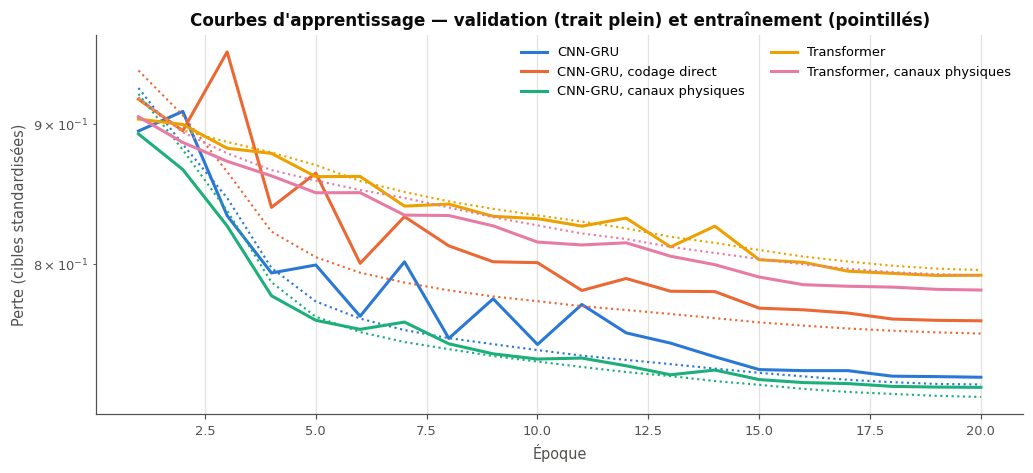

In [30]:
fig = plots.plot_learning_curves({label: run.history for label, run in RUNS.items()})
plt.show()

Les pertes du codage direct portent sur d'autres cibles : elles ne se comparent pas en valeur aux autres courbes. Un écart faible entre entraînement et validation indique l'absence de surapprentissage.

Les cinq modèles atteignent leur meilleure validation aux époques 19 ou 20 : les courbes baissent encore, l'entraînement n'a pas convergé. Avec les canaux physiques, la validation du CNN-GRU décroît sans les oscillations de la version de base (0,739 contre 0,748 à l'époque 10) : convergence plus rapide et plus stable.

## 7. Comparaison sur la validation

### 7.1 Vue d'ensemble

Validation — score = RMSE normalisée moyenne (plus petit = meilleur)


,score,R² HLC,R² Hb,R² CDT,paramètres,minutes
"CNN-GRU, canaux physiques",0.845,0.436,0.377,0.162,176133.000,10.645
"CNN-GRU, codage direct",0.848,0.425,0.366,0.165,175173.000,10.328
CNN-GRU,0.848,0.429,0.369,0.158,175173.000,10.362
"Transformer, canaux physiques",0.879,0.391,0.296,0.115,145733.000,8.665
Transformer,0.884,0.386,0.288,0.107,142661.000,8.617
Régression linéaire,0.947,0.246,0.126,0.037,NaN,NaN
Moyenne,1.000,-0.000,-0.000,-0.000,NaN,NaN


RMSE par indicateur (W/K pour les HLC, h pour les constantes de temps)


indicateur,HLC,HLC_mit,HLC_ext,tau_b,tau_n,tau_inf
Moyenne,31.409,26.256,17.121,10.163,2.020,7.581
Régression linéaire,27.271,23.519,16.650,10.154,1.916,7.546
CNN-GRU,23.740,22.438,12.480,9.510,1.741,7.220
"CNN-GRU, codage direct",23.819,22.489,12.524,9.462,1.740,7.174
"CNN-GRU, canaux physiques",23.585,22.363,12.358,9.482,1.737,7.207
Transformer,24.617,22.831,14.001,9.834,1.796,7.397
"Transformer, canaux physiques",24.519,22.789,13.845,9.777,1.789,7.367


P95 de l'erreur absolue par indicateur


indicateur,HLC,HLC_mit,HLC_ext,tau_b,tau_n,tau_inf
Moyenne,60.668,49.586,32.902,19.431,3.887,14.422
Régression linéaire,53.202,45.435,32.143,19.404,3.689,14.321
CNN-GRU,46.651,43.753,24.254,18.581,3.399,14.191
"CNN-GRU, codage direct",46.796,43.791,24.351,18.127,3.368,13.689
"CNN-GRU, canaux physiques",46.334,43.585,24.053,18.566,3.395,14.181
Transformer,48.270,44.398,27.325,19.318,3.531,14.656
"Transformer, canaux physiques",48.082,44.317,27.054,19.190,3.506,14.590


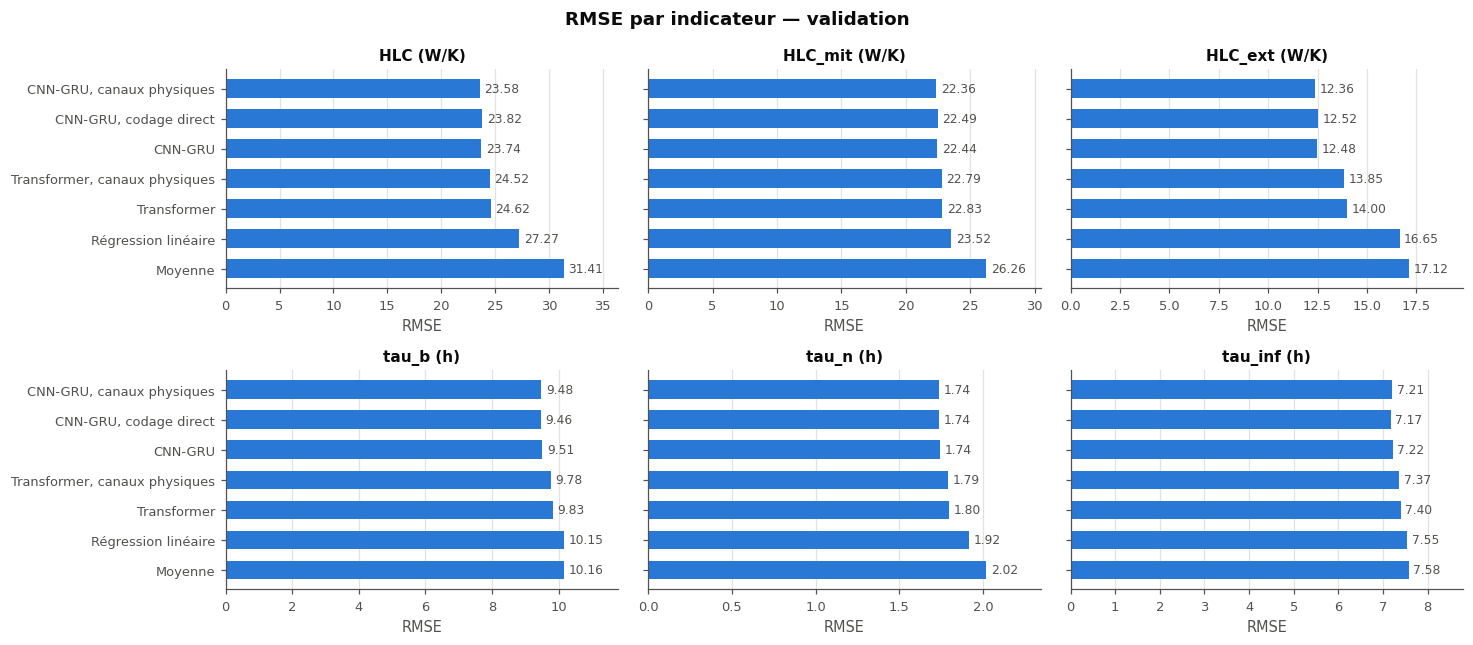

In [31]:
VAL_METRICS = {label: ca.regression_metrics(Y_VAL, pred, targets) for label, pred in VAL_PRED.items()}

summary = pd.DataFrame({
    label: {"score": ca.global_score(m),
            **{f"R² {fam}": v for fam, v in ca.family_summary(m)["R2"].items()},
            "paramètres": RUNS[label].n_parameters if label in RUNS else np.nan,
            "minutes": RUNS[label].train_seconds / 60 if label in RUNS else np.nan}
    for label, m in VAL_METRICS.items()}).T.sort_values("score")
print("Validation — score = RMSE normalisée moyenne (plus petit = meilleur)")
display(summary.round(4))

r2 = pd.DataFrame({label: m["R2"] for label, m in VAL_METRICS.items()}).T
rmse = pd.DataFrame({label: m["RMSE"] for label, m in VAL_METRICS.items()}).T
p95 = pd.DataFrame({label: m["P95"] for label, m in VAL_METRICS.items()}).T
print("RMSE par indicateur (W/K pour les HLC, h pour les constantes de temps)")
display(rmse.round(3))
print("P95 de l'erreur absolue par indicateur")
display(p95.round(3))

fig = plots.plot_model_comparison(rmse.loc[summary.index], "RMSE", "RMSE par indicateur — validation")
plt.show()

Les réseaux dépassent les références sur les HLC et `tau_n` ; `tau_b` et `tau_inf` restent proches de la moyenne, conformément à leur faible observabilité en 8 h (1.5). Le CNN-GRU devance le Transformer, surtout sur `HLC_ext` (RMSE de 12,5 contre 14,0 W/K) et `tau_b` (9,5 contre 9,8 h).

### 7.2 Par famille d'indicateurs

In [32]:
families = pd.concat({label: ca.family_summary(m)[["RMSE", "P95", "MAPE", "R2"]]
                      for label, m in VAL_METRICS.items()}, names=["modèle"])
display(families.unstack("famille").round(3))

RMSE                 P95                 MAPE  \
famille                          HLC     Hb   CDT    HLC     Hb    CDT    HLC   
modèle                                                                          
Moyenne                       31.409 21.689 6.588 60.668 41.244 12.580 11.195   
Régression linéaire           27.271 20.085 6.539 53.202 38.789 12.471  9.613   
CNN-GRU                       23.740 17.459 6.157 46.651 34.003 12.057  8.300   
CNN-GRU, codage direct        23.819 17.507 6.125 46.796 34.071 11.728  8.334   
CNN-GRU, canaux physiques     23.585 17.360 6.142 46.334 33.819 12.047  8.250   
Transformer                   24.617 18.416 6.343 48.270 35.862 12.502  8.641   
Transformer, canaux physiques 24.519 18.317 6.311 48.082 35.686 12.429  8.582   

                                                R2                
famille                           Hb    CDT    HLC     Hb    CDT  
modèle                                                            
Moyenne                       15.941 16.963 -0.000 -0.000 -0.000  
Régression linéaire           14.613 16.667  0.246  0.126  0.037  
CNN-GRU                       12.505 15.011  0.429  0.369  0.158  
CNN-GRU, codage direct        12.552 15.492  0.425  0.366  0.165  
CNN-GRU, canaux physiques     12.433 14.962  0.436  0.377  0.162  
Transformer                   13.266 15.311  0.386  0.288  0.107  
Transformer, canaux physiques 13.161 15.302  0.391  0.296  0.115

L'ordre des familles est le même pour tous les réseaux : HLC (R² de 0,39 à 0,44), puis Hb (0,29 à 0,38), puis CDT (0,11 à 0,17), celui de l'observabilité attendue en 1.5.

### 7.3 Codage contraint ou direct

In [33]:
pair = ["CNN-GRU", "CNN-GRU, codage direct"]
display(pd.concat({label: VAL_METRICS[label][["RMSE", "P95", "R2"]] for label in pair}, axis=1).round(3))

viol = pd.DataFrame({label: ca.constraint_violations(VAL_PRED[label], targets) for label in VAL_PRED}).T * 100
print("Prédictions violant une contrainte physique (%)")
display(viol.round(3))

CNN-GRU              CNN-GRU, codage direct             
              RMSE    P95    R2                   RMSE    P95    R2
indicateur                                                         
HLC         23.740 46.651 0.429                 23.819 46.796 0.425
HLC_mit     22.438 43.753 0.270                 22.489 43.791 0.266
HLC_ext     12.480 24.254 0.469                 12.524 24.351 0.465
tau_b        9.510 18.581 0.124                  9.462 18.127 0.133
tau_n        1.741  3.399 0.257                  1.740  3.368 0.258
tau_inf      7.220 14.191 0.093                  7.174 13.689 0.104

Prédictions violant une contrainte physique (%)


,somme_HLC,ordre_tau,valeurs_negatives
Moyenne,0.000,0.000,0.000
Régression linéaire,0.000,0.000,0.000
CNN-GRU,0.000,0.000,0.000
"CNN-GRU, codage direct",0.000,0.000,0.000
"CNN-GRU, canaux physiques",0.000,0.000,0.000
Transformer,0.000,0.000,0.000
"Transformer, canaux physiques",0.000,0.000,0.000


Précision comparable entre les deux codages ; seul le codage contraint garantit 0 % de violation. Il est retenu. En pratique, le codage direct ne viole pas non plus l'ordre : les écarts moyens entre constantes de temps (environ 20 h, section 3.1) sont grands devant les erreurs.

### 7.4 Effet des canaux physiques

In [34]:
gain = pd.DataFrame({
    arch: 100 * (rmse.loc[f"{arch}, canaux physiques"] / rmse.loc[arch] - 1)
    for arch in ("CNN-GRU", "Transformer")}).T
print("Variation de la RMSE avec les canaux physiques (%, négatif = amélioration)")
display(gain.round(1))

Variation de la RMSE avec les canaux physiques (%, négatif = amélioration)


indicateur,HLC,HLC_mit,HLC_ext,tau_b,tau_n,tau_inf
CNN-GRU,-0.700,-0.300,-1.000,-0.300,-0.300,-0.200
Transformer,-0.400,-0.200,-1.100,-0.600,-0.400,-0.400


Les canaux physiques sont calculés à partir de T et U : ils n'apportent pas d'information nouvelle. Un gain faible signifie que le réseau extrait déjà seul la réponse au chauffage et la position dans la météo. Le gain mesuré, de 0,2 à 1,1 % de RMSE, le confirme ; il est le plus net sur `HLC_ext`.

### 7.5 Par régime d'excitation

Modèle retenu : CNN-GRU, canaux physiques


régime,tout,avec créneaux,sans excitation,toujours allumé
indicateur,,,,
HLC,0.436,0.450,0.278,0.455
HLC_mit,0.275,0.284,0.172,0.244
HLC_ext,0.479,0.478,0.492,0.508
tau_b,0.129,0.124,0.189,0.090
tau_n,0.261,0.262,0.242,0.298
tau_inf,0.096,0.092,0.140,0.086


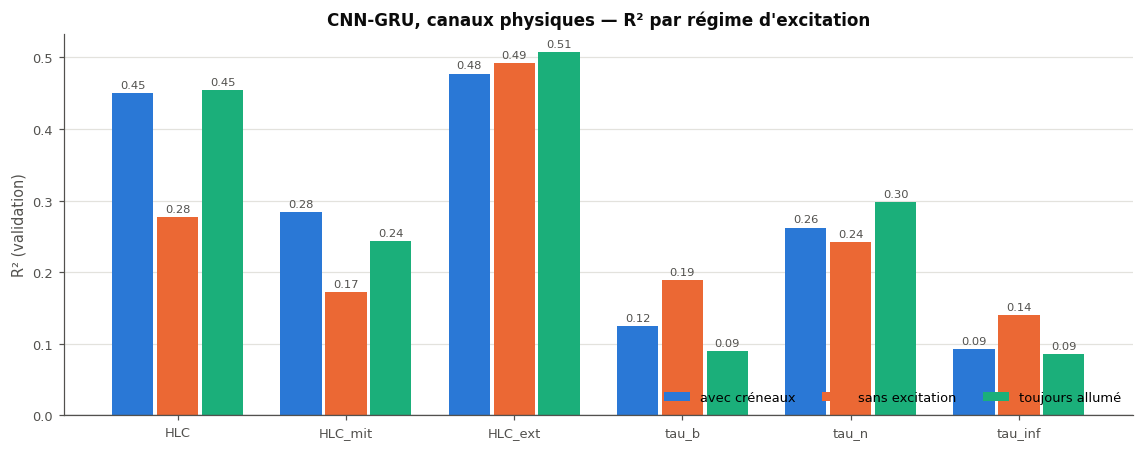

In [35]:
BEST = summary.index[[label in RUNS for label in summary.index]][0]      # meilleur réseau en validation
print("Modèle retenu :", BEST)

by_group = ca.metrics_by_group(Y_VAL, VAL_PRED[BEST], targets, GROUPS_VAL)
display(by_group["R2"].unstack("régime").round(3))
fig = plots.plot_group_bars(by_group["R2"].unstack("régime")[list(GROUPS_VAL)].loc[targets],
                            "R² (validation)", f"{BEST} — R² par régime d'excitation")
plt.show()

Le chauffage révèle surtout le HLC et sa part mitoyenne ; la météo commune, qui agit comme une seconde excitation, suffit à révéler `HLC_ext` ; les créneaux de 7 kW masquent la dérive lente où se lisent les constantes de temps longues.

## 8. Modèle retenu : test et analyse des erreurs

Le test n'a servi à aucune décision : il est utilisé une seule fois.

### 8.1 Résultats sur le test

In [36]:
best_run = RUNS[BEST]
Y_TEST = Y[SPLITS["test"]]
GROUPS_TEST = {k: m[SPLITS["test"]] for k, m in GROUPS.items()}
TEST_PRED = ca.predict(best_run.model, data_dev, SPLITS["test"], scaler_dev, best_run.codec,
                       best_run.experiment.inputs)

test_metrics = ca.regression_metrics(Y_TEST, TEST_PRED, targets)
test_metrics.insert(0, "unité", [ca.UNITS[t] for t in targets])
print(f"{BEST} — test ({len(Y_TEST)} simulations)")
display(test_metrics.round(3))
print("Par famille")
display(ca.family_summary(test_metrics.drop(columns="unité")).round(3))
print("Contraintes physiques violées (%) :",
      {k: round(100 * v, 3) for k, v in ca.constraint_violations(TEST_PRED, targets).items()})

compare = pd.DataFrame({"validation": VAL_METRICS[BEST]["RMSE"], "test": test_metrics["RMSE"]})
compare["écart (%)"] = 100 * (compare["test"] / compare["validation"] - 1)
print("RMSE : validation contre test")
display(compare.round(3))

CNN-GRU, canaux physiques — test (99999 simulations)


,unité,RMSE,MAE,P95,MAPE,R2
indicateur,,,,,,
HLC,W/K,23.503,18.779,46.111,8.216,0.441
HLC_mit,W/K,22.250,17.892,43.386,15.730,0.283
HLC_ext,W/K,12.320,9.878,23.954,9.034,0.483
tau_b,h,9.427,7.318,18.560,14.680,0.132
tau_n,h,1.722,1.344,3.350,12.168,0.264
tau_inf,h,7.158,5.512,14.078,17.825,0.098


Par famille


,RMSE,MAE,P95,MAPE,R2
famille,,,,,
HLC,23.503,18.779,46.111,8.216,0.441
Hb,17.285,13.885,33.670,12.382,0.383
CDT,6.102,4.725,11.996,14.891,0.165


Contraintes physiques violées (%) : {'somme_HLC': 0.0, 'ordre_tau': 0.0, 'valeurs_negatives': 0.0}
RMSE : validation contre test


,validation,test,écart (%)
indicateur,,,
HLC,23.585,23.503,-0.345
HLC_mit,22.363,22.250,-0.504
HLC_ext,12.358,12.320,-0.308
tau_b,9.482,9.427,-0.582
tau_n,1.737,1.722,-0.867
tau_inf,7.207,7.158,-0.677


Un écart faible entre validation et test indique que la sélection du modèle n'a pas surajusté la validation. Ici, les écarts sont inférieurs à 1 % sur les six indicateurs.

### 8.2 Prédiction contre référence

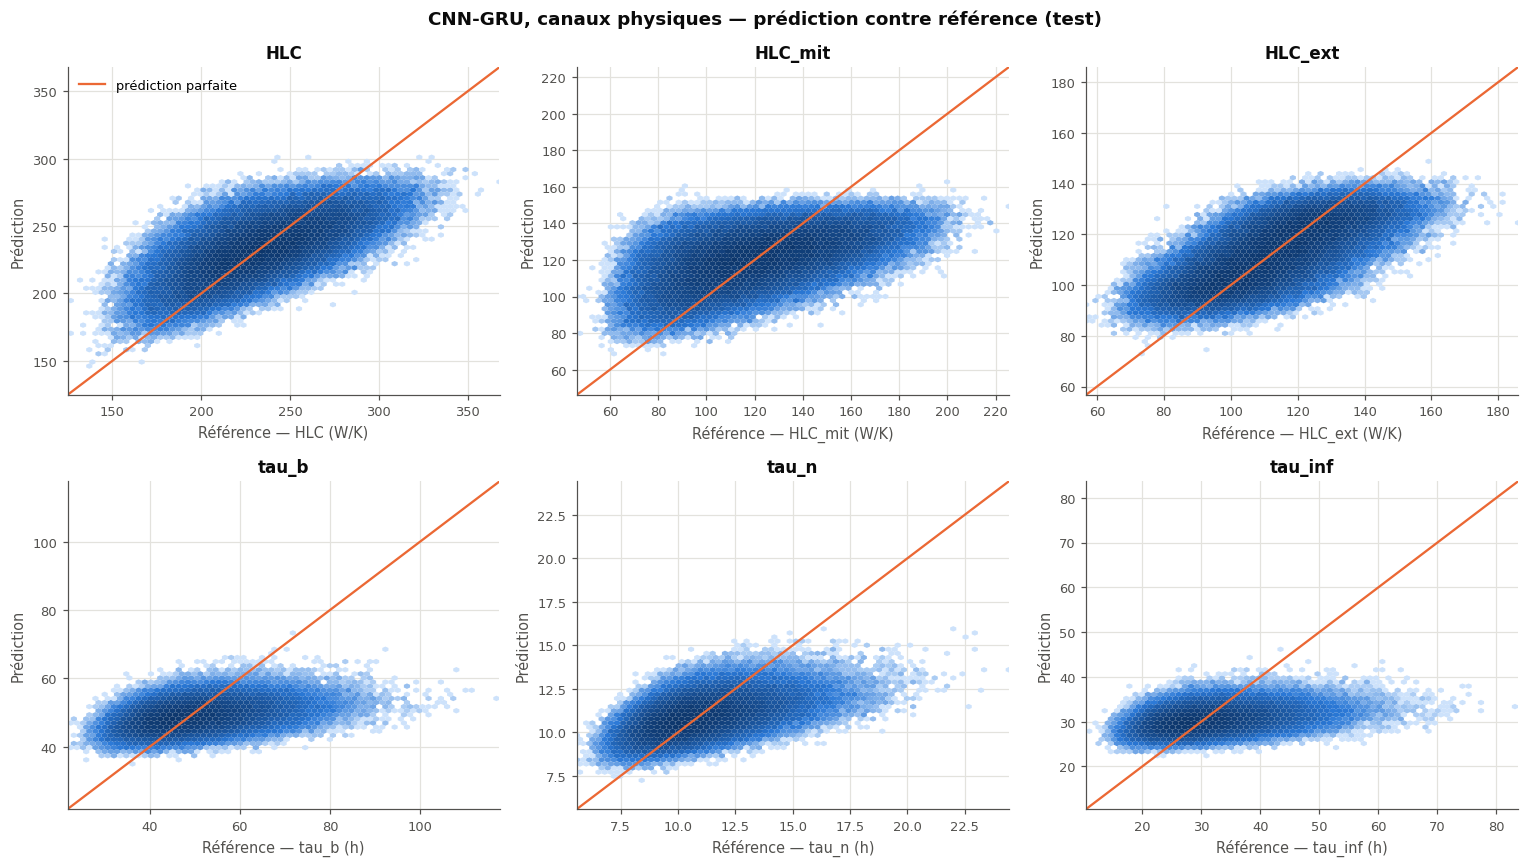

,biais moyen,"biais, tiers inférieur","biais, tiers supérieur"
HLC,0.159,18.953,-20.084
HLC_mit,0.119,20.342,-21.658
HLC_ext,0.040,9.372,-9.810
tau_b,-1.076,7.612,-10.932
tau_n,-0.119,1.338,-1.807
tau_inf,-0.854,5.764,-8.476


In [37]:
fig = plots.plot_parity(Y_TEST, TEST_PRED, targets, f"{BEST} — prédiction contre référence (test)")
plt.show()

err = TEST_PRED - Y_TEST
bias = pd.DataFrame({"biais moyen": err.mean(0).numpy(),
                     "biais, tiers inférieur": [err[Y_TEST[:, j] <= Y_TEST[:, j].quantile(1 / 3), j].mean().item() for j in range(6)],
                     "biais, tiers supérieur": [err[Y_TEST[:, j] >= Y_TEST[:, j].quantile(2 / 3), j].mean().item() for j in range(6)]},
                    index=targets)
display(bias.round(3))

Un biais positif dans le tiers inférieur et négatif dans le tiers supérieur traduit une **régression vers la moyenne** : quand l'information manque, le modèle se replie sur la valeur moyenne.

### 8.3 Erreur par régime d'excitation

In [38]:
test_by_group = ca.metrics_by_group(Y_TEST, TEST_PRED, targets, GROUPS_TEST)
display(test_by_group[["RMSE", "P95", "R2"]].unstack("régime").round(3))

RMSE                                                  P95  \
régime       tout avec créneaux sans excitation toujours allumé   tout   
indicateur                                                               
HLC        23.503        23.191          26.750          22.192 46.111   
HLC_mit    22.250        22.095          23.903          21.826 43.386   
HLC_ext    12.320        12.344          12.100          11.813 23.954   
tau_b       9.427         9.466           9.007           9.294 18.560   
tau_n       1.722         1.721           1.735           1.663  3.350   
tau_inf     7.158         7.183           6.903           6.985 14.078   

                                                            R2                \
régime     avec créneaux sans excitation toujours allumé  tout avec créneaux   
indicateur                                                                     
HLC               45.521          51.274          43.373 0.441         0.454   
HLC_mit           43.139          45.217          43.243 0.283         0.292   
HLC_ext           23.993          23.591          22.870 0.483         0.480   
tau_b             18.626          17.711          18.076 0.132         0.125   
tau_n              3.347           3.376           3.295 0.264         0.265   
tau_inf           14.127          13.592          13.776 0.098         0.092   

                                            
régime     sans excitation toujours allumé  
indicateur                                  
HLC                  0.291           0.498  
HLC_mit              0.183           0.336  
HLC_ext              0.502           0.516  
tau_b                0.212           0.144  
tau_n                0.248           0.305  
tau_inf              0.160           0.114

Le test confirme la lecture de 7.5 : sans excitation, le R² du HLC tombe à 0,29 (0,45 avec créneaux), tandis que celui de `HLC_ext` reste à 0,50.

### 8.4 Erreur en fonction de l'excitation

Comme dans l'article, l'erreur est calculée par tranches d'un descripteur de l'excitation (simulations chauffées du test).

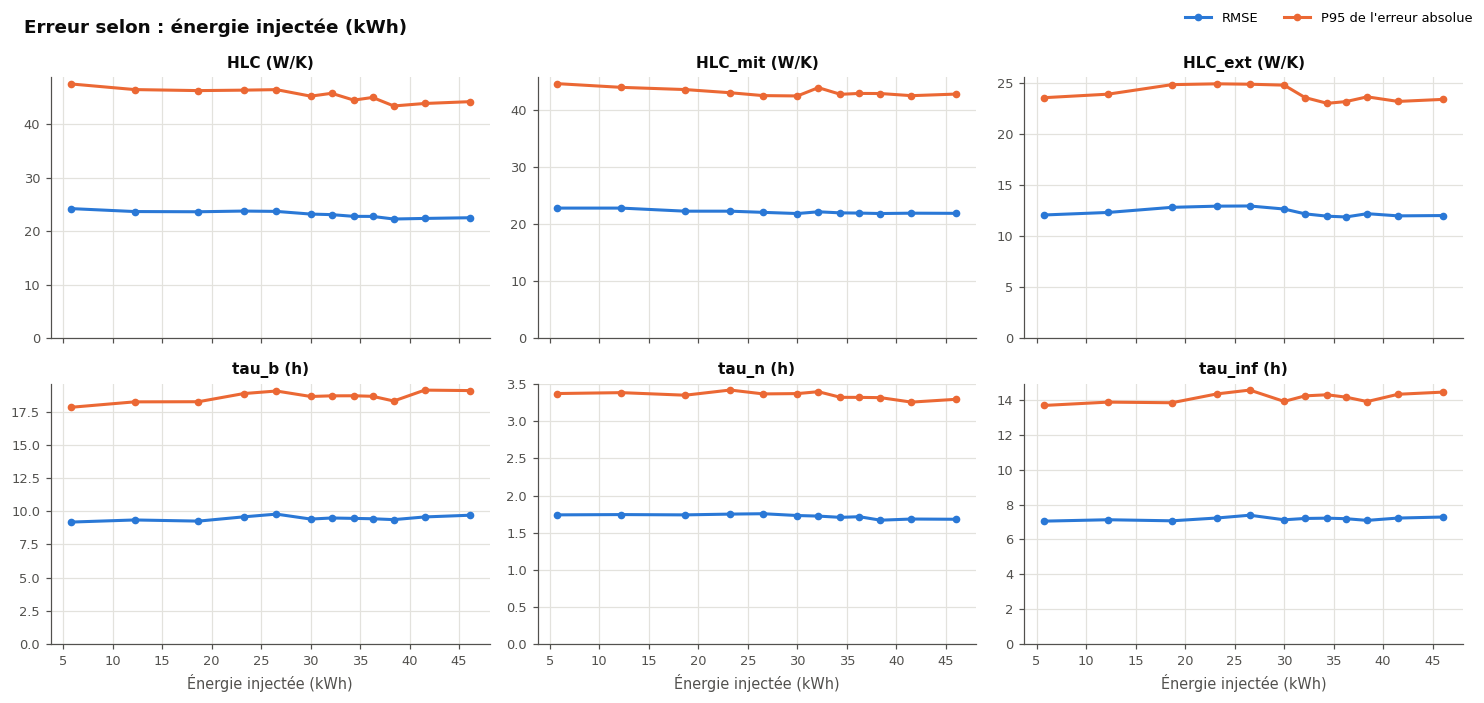

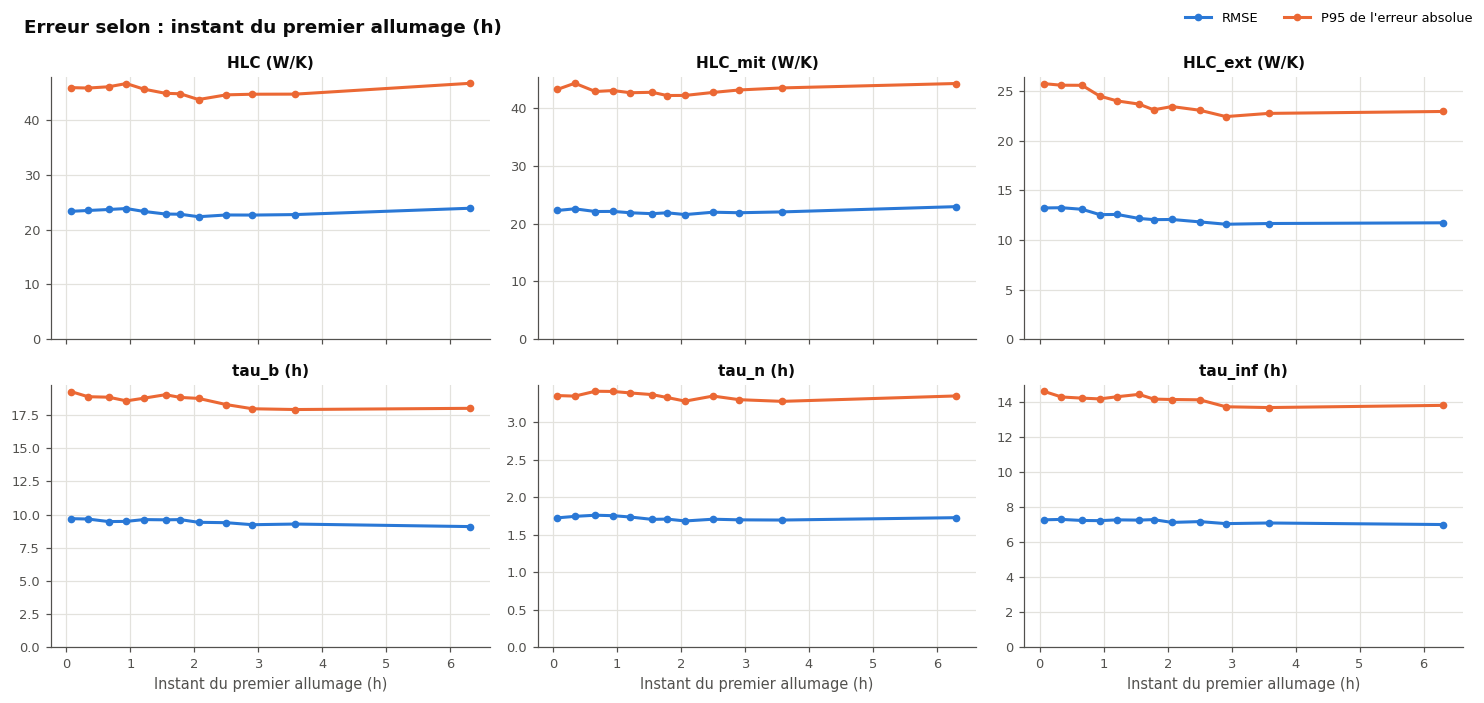

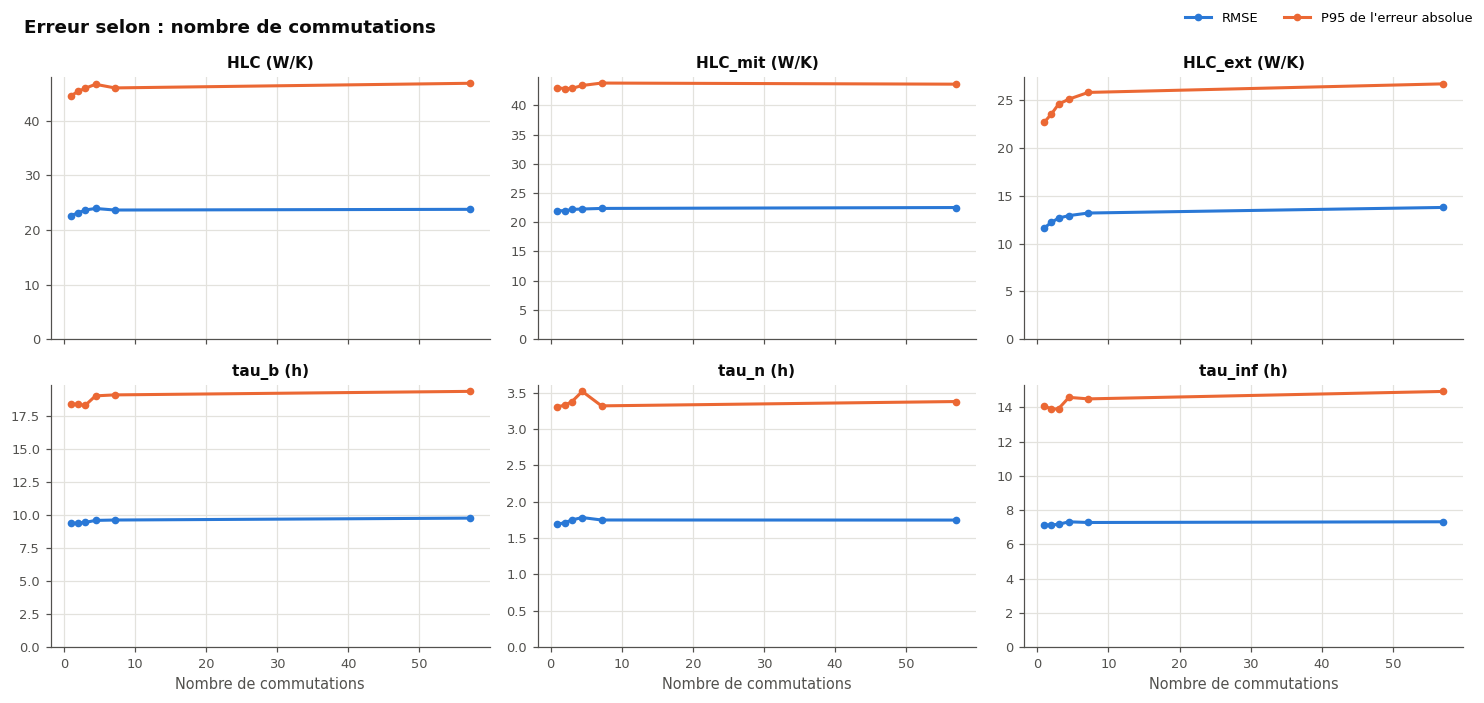

In [39]:
heated = ~GROUPS_TEST["sans excitation"]
desc_test = {k: v[SPLITS["test"]] for k, v in desc.items()}
for key, xlabel in [("energie_kWh", "Énergie injectée (kWh)"),
                    ("premier_allumage_h", "Instant du premier allumage (h)"),
                    ("n_commutations", "Nombre de commutations")]:
    table = plots.binned_errors(desc_test[key][heated], Y_TEST[heated], TEST_PRED[heated], targets)
    table.to_csv(RES / f"erreur_selon_{key}.csv", index=False)
    fig = plots.plot_binned_errors(table, targets, xlabel, f"Erreur selon : {xlabel[0].lower() + xlabel[1:]}")
    plt.show()

L'erreur dépend peu de l'excitation : la RMSE du HLC passe d'environ 24,2 à 22,5 W/K entre 6 et 46 kWh injectés. `HLC_ext` est mieux estimé quand le chauffage démarre tard (13,2 → 11,7 W/K) et moins bien avec des commutations nombreuses (11,6 → 13,8 W/K) : une longue phase libre renseigne sur l'extérieur. La limite tient moins à l'excitation qu'à la durée de mesure et à l'état initial inconnu.

### 8.5 Erreur en fonction de la valeur de l'indicateur

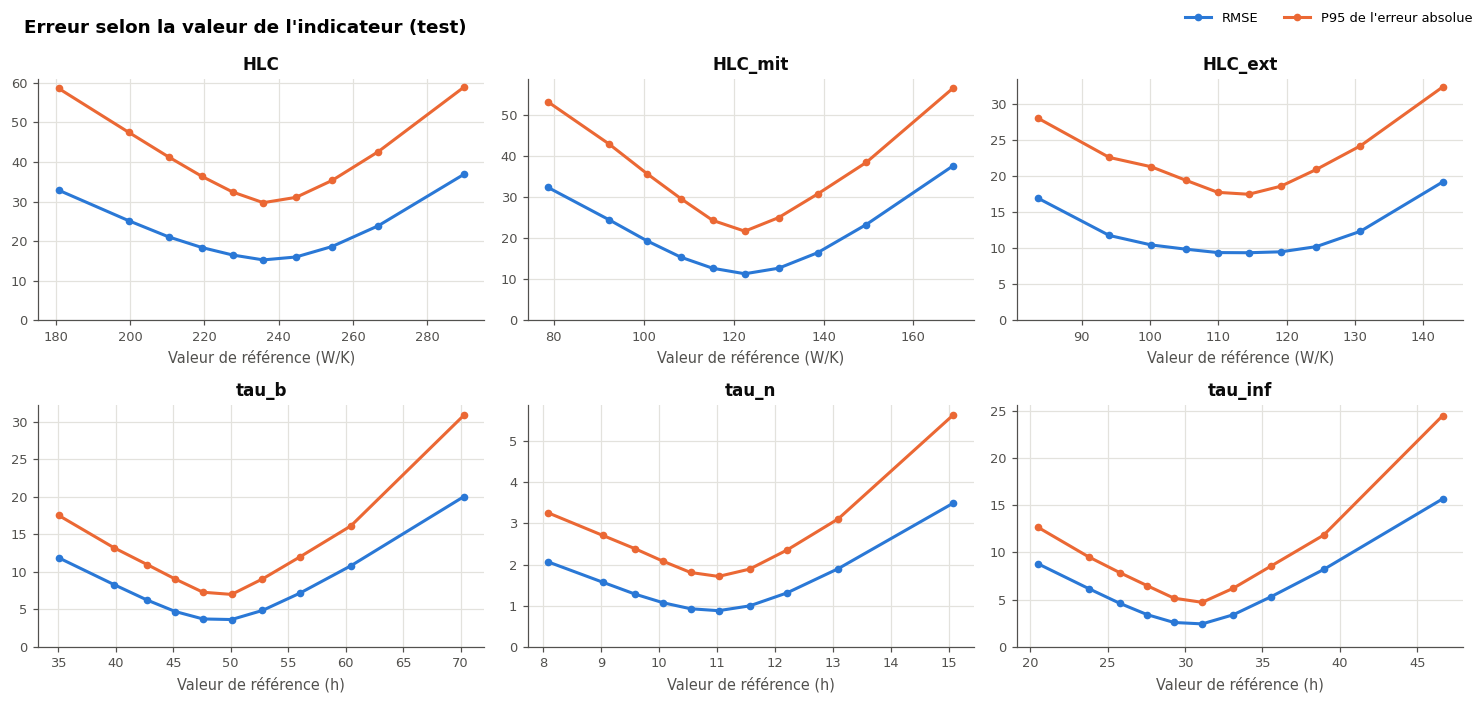

In [40]:
rows = []
for j, name in enumerate(targets):
    table = plots.binned_errors(Y_TEST[:, j], Y_TEST, TEST_PRED, targets, n_bins=10)
    rows.append(table[table["indicateur"] == name])
by_value = pd.concat(rows)
fig, axes = plt.subplots(2, 3, figsize=(13.5, 6.4))
for ax, name in zip(axes.flat, targets):
    sub = by_value[by_value["indicateur"] == name]
    ax.plot(sub["centre"], sub["RMSE"], marker="o", ms=4, label="RMSE")
    ax.plot(sub["centre"], sub["P95"], marker="o", ms=4, label="P95 de l'erreur absolue")
    ax.set(title=name, xlabel=f"Valeur de référence ({ca.UNITS[name]})")
    ax.set_ylim(bottom=0)
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="upper right", ncols=2)
fig.suptitle("Erreur selon la valeur de l'indicateur (test)", fontweight="bold", x=0.02, ha="left")
fig.tight_layout()
plt.show()

L'erreur est minimale au centre et croît aux extrêmes, signature de la régression vers la moyenne (8.2). Pour les constantes de temps, elle croît surtout vers les grandes valeurs : la RMSE de `tau_b` atteint environ 20 h pour les bâtiments les plus inertes, contre 12 h pour les moins inertes.

### 8.6 Robustesse au bruit de mesure

Une sonde réelle a une précision d'environ ±0,25 °C. Un second modèle est entraîné avec ce bruit, puis les deux sont évalués avec un bruit croissant à la prédiction.

In [41]:
noisy_exp = ca.Experiment(**{**asdict(best_run.experiment), "name": best_run.experiment.name + "_bruit",
                             "noise_c": NOISE_C})
noisy_run = ca.run_experiment(noisy_exp, data_dev, SPLITS, scaler_dev, CKPT, retrain=RETRAIN)

[cnn_gru_physique_contraint_bruit] époque   1/20 | train 0.9244 | val 0.9070 | lr 5.2e-04 | 32 s
[cnn_gru_physique_contraint_bruit] époque   2/20 | train 0.8857 | val 0.8874 | lr 1.0e-03 | 32 s
[cnn_gru_physique_contraint_bruit] époque   3/20 | train 0.8705 | val 0.8673 | lr 9.9e-04 | 32 s
[cnn_gru_physique_contraint_bruit] époque   4/20 | train 0.8646 | val 0.8640 | lr 9.7e-04 | 32 s
[cnn_gru_physique_contraint_bruit] époque   5/20 | train 0.8616 | val 0.8618 | lr 9.3e-04 | 32 s
[cnn_gru_physique_contraint_bruit] époque   6/20 | train 0.8593 | val 0.8615 | lr 8.8e-04 | 32 s
[cnn_gru_physique_contraint_bruit] époque   7/20 | train 0.8580 | val 0.8534 | lr 8.2e-04 | 32 s
[cnn_gru_physique_contraint_bruit] époque   8/20 | train 0.8565 | val 0.8524 | lr 7.5e-04 | 32 s
[cnn_gru_physique_contraint_bruit] époque   9/20 | train 0.8553 | val 0.8491 | lr 6.7e-04 | 32 s
[cnn_gru_physique_contraint_bruit] époque  10/20 | train 0.8537 | val 0.8479 | lr 5.9e-04 | 32 s
[cnn_gru_physique_contraint_br

,,score,HLC,HLC_mit,HLC_ext,tau_b,tau_n,tau_inf
modèle,bruit à la prédiction (°C),,,,,,,
entraîné sans bruit,0.000,0.845,23.585,22.363,12.358,9.482,1.737,7.207
entraîné avec 0.25 °C de bruit,0.000,0.909,25.346,22.874,15.367,10.001,1.834,7.484
entraîné sans bruit,0.050,0.974,27.948,23.893,17.483,10.475,1.968,7.738
entraîné avec 0.25 °C de bruit,0.050,0.909,25.356,22.874,15.378,10.001,1.835,7.484
entraîné sans bruit,0.100,0.991,28.697,23.994,18.169,10.498,2.022,7.775
entraîné avec 0.25 °C de bruit,0.100,0.910,25.392,22.877,15.421,10.006,1.837,7.487
entraîné sans bruit,0.250,0.997,29.135,23.948,18.408,10.376,2.076,7.737
entraîné avec 0.25 °C de bruit,0.250,0.917,25.646,22.907,15.714,10.035,1.851,7.503
entraîné sans bruit,0.500,1.010,30.026,24.366,18.398,10.300,2.174,7.667


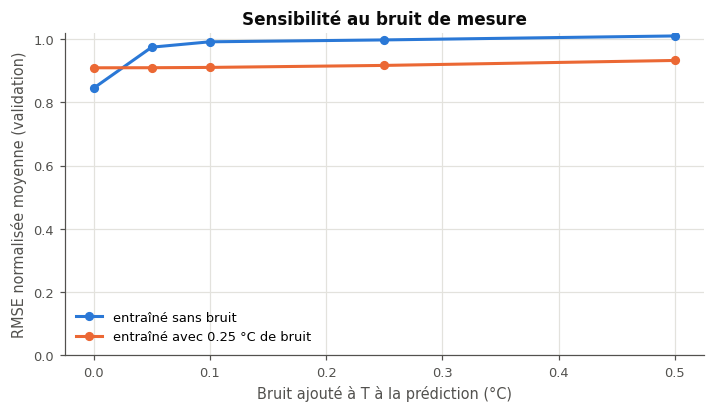

In [42]:
rows = {}
for sigma in (0.0, 0.05, 0.1, 0.25, 0.5):
    for label, run in [("entraîné sans bruit", best_run), (f"entraîné avec {NOISE_C} °C de bruit", noisy_run)]:
        pred = ca.predict(run.model, data_dev, SPLITS["val"], scaler_dev, run.codec,
                          run.experiment.inputs, noise_c=sigma, seed=SEED)
        m = ca.regression_metrics(Y_VAL, pred, targets)
        rows[(label, sigma)] = {"score": ca.global_score(m), **m["RMSE"].to_dict()}
noise_table = pd.DataFrame(rows).T.rename_axis(["modèle", "bruit à la prédiction (°C)"])
noise_table.to_csv(RES / "robustesse_bruit.csv")
display(noise_table.round(3))

fig, ax = plt.subplots(figsize=(7.5, 3.8))
for label in noise_table.index.get_level_values(0).unique():
    sub = noise_table.loc[label]
    ax.plot(sub.index, sub["score"], marker="o", ms=5, label=label)
ax.set(xlabel="Bruit ajouté à T à la prédiction (°C)", ylabel="RMSE normalisée moyenne (validation)",
       title="Sensibilité au bruit de mesure")
ax.set_ylim(bottom=0)
ax.legend()
plt.show()

Le modèle entraîné sans bruit est très fragile : 0,05 °C suffit à faire passer son score de 0,845 à 0,974, et à 0,25 °C il ne fait pas mieux que la moyenne (0,997). Le modèle entraîné avec 0,25 °C de bruit perd sur des données propres (0,909) mais reste stable (0,917 à 0,25 °C, 0,932 à 0,5 °C) : c'est lui qu'il faut utiliser sur des mesures réelles, comme dans l'article.

### 8.7 Sauvegarde des résultats

In [43]:
results = {
    "config": {"quick": QUICK, "epochs": EPOCHS, "seed": SEED, "n_simulations": N, "device": str(DEVICE),
               "splits": {k: len(v) for k, v in SPLITS.items()}},
    "experiments": {label: {**asdict(run.experiment), "n_parameters": run.n_parameters,
                            "best_epoch": run.best_epoch, "train_minutes": run.train_seconds / 60,
                            "history": run.history} for label, run in RUNS.items()},
    "validation": {label: m.to_dict(orient="index") for label, m in VAL_METRICS.items()},
    "validation_scores": summary["score"].to_dict(),
    "validation_violations_pct": viol.to_dict(orient="index"),
    "best_model": BEST,
    "validation_by_group": {str(k): v for k, v in by_group.to_dict(orient="index").items()},
    "test": test_metrics.drop(columns="unité").to_dict(orient="index"),
    "test_by_group": {str(k): v for k, v in test_by_group.to_dict(orient="index").items()},
    "test_bias": bias.to_dict(orient="index"),
    "noise": {str(k): v for k, v in noise_table.to_dict(orient="index").items()},
    "eda": {"targets": stats.drop(columns="unité").to_dict(orient="index"),
            "corr_always_on": corr_on.to_dict(orient="index"),
            "groups_pct": {k: 100 * v.float().mean().item() for k, v in GROUPS.items()}},
}
(RES / "results.json").write_text(json.dumps(results, indent=1, ensure_ascii=False), encoding="utf-8")
summary.to_csv(RES / "validation_resume.csv")
rmse.to_csv(RES / "validation_rmse.csv")
test_metrics.to_csv(RES / "test_metriques.csv")
np.savez_compressed(RES / "test_predictions.npz", y_true=Y_TEST.numpy(), y_pred=TEST_PRED.numpy(),
                    idx=SPLITS["test"].numpy())
print("Fichiers écrits dans", RES, ":", sorted(p.name for p in RES.iterdir()))

Fichiers écrits dans /kaggle/working/outputs/results : ['erreur_selon_energie_kWh.csv', 'erreur_selon_n_commutations.csv', 'erreur_selon_premier_allumage_h.csv', 'results.json', 'robustesse_bruit.csv', 'test_metriques.csv', 'test_predictions.npz', 'validation_resume.csv', 'validation_rmse.csv']


## 9. Limites et perspectives

**Réponses aux questions posées**

| Question | Réponse |
|---|---|
| Codage contraint ou direct ? | Précision identique ; le contraint garantit les contraintes : retenu |
| Canaux physiques ? | Gain de 0,2 à 1,1 % de RMSE ; convergence plus rapide et plus stable |
| Architecture ? | CNN-GRU (score 0,845) devant le Transformer (0,879) |
| Mesures réelles ? | Seul le modèle entraîné avec bruit reste utilisable (score 0,917 à 0,25 °C) |

**Limites**

- **Un seul bâtiment, une seule météo** : le modèle est spécifique à cette configuration, comme dans l'article, qui réentraîne un modèle par bâtiment et par essai.
- **Données simulées** : hypothèses du simulateur (zones isothermes, transferts 1D, ni infiltrations ni occupants) ; seule la robustesse au bruit de capteur est évaluée.
- **Identifiabilité** : 8 h sont courtes devant les grandes constantes de temps, et une partie des simulations n'a aucune excitation. Plusieurs architectures plafonnent au même niveau : la limite tient à l'information disponible.
- **Entraînement non convergé** : les meilleures validations sont aux dernières époques ; plus d'époques amélioreraient un peu les scores.
- **Une seule graine** par expérience ; **pas d'incertitude** sur les prédictions.

**Perspectives**

- **Prédire l'incertitude** (moyenne et variance) pour signaler les mesures peu informatives.
- **Choisir l'excitation** à partir de l'analyse 8.4, pour les six indicateurs à la fois.
- **Ajouter la météo en entrée** pour séparer explicitement réponse libre et réponse au chauffage.
- **Réduire la durée de mesure** (6, 4, 2 h) pour tracer la précision en fonction de la durée de l'essai.